# H16: Cluster-Based Cell Phenotyping (Independent Pipeline with RESTORE Normalization)
**Loads raw data from Cells.csv, applies morphological + signal QC, RESTORE intensity
normalization, fresh UMAP/Leiden, then overclustering + signature scoring for cell typing.**

Key improvements over H15:
- Independent data pipeline (no H15 checkpoint dependency)
- Robust morphological + signal quality filtering
- RESTORE normalization on raw intensities using mutually exclusive marker pairs
- Fresh embedding and clustering from scratch

In [1]:
import os
os.environ["NUMBA_NUM_THREADS"] = "64"
os.environ["OMP_NUM_THREADS"] = "64"
os.environ["OPENBLAS_NUM_THREADS"] = "64"

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist
from scipy.spatial import cKDTree
from scipy.stats import entropy
from sklearn.neighbors import KNeighborsClassifier
from sklearn.mixture import GaussianMixture
from joblib import Parallel, delayed
from pathlib import Path
from harmonypy import run_harmony

from data_utils import (
    extract_sample_id, GENOTYPE_MAP, CODEX_SAMPLES, EXCLUDE_SAMPLES,
    GENO_ORDER, GENO_PALETTE, MAIN_REGIONS, REGION_ORDER,
    assign_regions_by_image, load_region_layer, signed_distance_by_image,
    full_stats_table, platform_diagnostic, save_figure, save_table,
    setup_style, PROJECT, DATA_CSV,
)

setup_style()
sc.settings.verbosity = 2

# ---------------------------------------------------------------------------
# Marker definitions (matching H15)
# ---------------------------------------------------------------------------
CELLS_CSV = PROJECT / "Measurements" / "Cells.csv"

# 18 exact-match markers (same column name in both platforms)
COMMON_MARKERS_EXACT = [
    "CD45RO", "Ki67", "CD20", "CD4", "CD44", "CD31", "CD11c", "CD34",
    "CD107a", "CD163", "HLA-DR", "CD68", "CD8", "CD21", "Vimentin",
    "CD3e", "CD45", "Podoplanin",
]

# 4 harmonizable markers: (canonical, phenocycler_col, codex_col)
HARMONIZE = [
    ("FOXP3",      "Cell: FOXP3: Mean",       "Cell: FoxP3: Mean"),
    ("SMA",        "Cell: SMA: Mean",          "Cell: SMActin: Mean"),
    ("CollagenIV", "Cell: Collagen IV: Mean",  "Cell: CollagenIV: Mean"),
    ("Ecadherin",  "Cell: E-cadherin: Mean",   "Cell: ECAD: Mean"),
]

ALL_MARKERS = COMMON_MARKERS_EXACT + [h[0] for h in HARMONIZE]  # 22 (for loading/harmonizing)

# Exclude CollagenIV and Ecadherin from clustering — they dominate PCA
# because they have no RESTORE pairs and retain raw intensity scale
EXCLUDED_FROM_CLUSTERING = {"CollagenIV", "Ecadherin"}
CLUSTERING_MARKERS = [m for m in ALL_MARKERS if m not in EXCLUDED_FROM_CLUSTERING]  # 20

# Core lineage-discriminating markers for PCA/UMAP embedding
# Drops broadly-expressed / non-lineage markers (CD44, CD45, CD45RO, Ki67,
# CD107a, HLA-DR, CD34, Podoplanin) that add noise to the embedding
EMBEDDING_MARKERS = [
    "CD20", "CD3e", "CD4", "CD8", "FOXP3", "CD68", "CD163",
    "CD11c", "CD21", "CD31", "Vimentin", "SMA",
]

MARKER_COLS_EXACT = [f"Cell: {m}: Mean" for m in COMMON_MARKERS_EXACT]
HARMONIZE_COLS = [col for _, pc, cx in HARMONIZE for col in (pc, cx)]

# ---------------------------------------------------------------------------
# Column definitions
# ---------------------------------------------------------------------------
X_COL, Y_COL = "Centroid X µm", "Centroid Y µm"
DIST_COLS = [
    "Signed distance to annotation Follicle µm",
    "Signed distance to annotation PALS µm",
    "Signed distance to annotation RedPulp µm",
    "Signed distance to annotation SmallVessel µm",
    "Signed distance to annotation LargeVessel µm",
    "Signed distance to annotation Trabeculae µm",
]
META_COLS = ["Image", "Object ID", X_COL, Y_COL, "Cell: Area µm^2"]

# Morphology columns for QC
MORPH_COLS = [
    "Nucleus: Area µm^2", "Cell: Area µm^2",
    "Nucleus/Cell area ratio", "Nucleus: Circularity", "Nucleus: Solidity",
]
DAPI_COL = "Cell: DAPI: Mean"

# Deduplicated column list for CSV loading
USE_COLS = list(dict.fromkeys(
    META_COLS + MORPH_COLS + [DAPI_COL] + MARKER_COLS_EXACT + HARMONIZE_COLS + DIST_COLS
))

# ---------------------------------------------------------------------------
# Crop parameters (matching H14/H15)
# ---------------------------------------------------------------------------
# ── Cropping is DISABLED: Phenocycler sections are analysed whole ──
# Cropping them to a CODEX-sized window was a mitigation for the ~10x difference
# in imaged area. It is abandoned. It discarded 75-88% of the data to address
# only the first of the four confound mechanisms — unequal effort — and left
# field selection, optical resolution and detection sensitivity untouched. A
# larger section yields a more precise estimate, not a biased one; H20's
# count-rate model with an area offset is the replacement.
#
# The thresholds are pushed beyond any real extent rather than deleted, so the
# machinery below still runs and returns "no crop" for every sample. That keeps
# the downstream guards exercised rather than leaving dead branches behind.
CROP_W, CROP_H = 5000, 3000
CROP_THRESHOLD_X, CROP_THRESHOLD_Y = np.inf, np.inf
CROP_OVERRIDES = {"HDL011": (2000, 2000)}
ARCSINH_COFACTOR = 150

# ---------------------------------------------------------------------------
# QC thresholds
# ---------------------------------------------------------------------------
NUC_AREA_MIN, NUC_AREA_MAX = 5, 200       # µm²
CELL_AREA_MIN, CELL_AREA_MAX = 10, 500    # µm²
NC_RATIO_MIN, NC_RATIO_MAX = 0.1, 1.0
NUC_CIRC_MIN = 0.15
NUC_SOL_MIN = 0.5
MAX_ZERO_MARKERS = 18   # of 22 clustering markers
ZERO_THRESHOLD = 1.0    # raw intensity < 1.0 counts as "near-zero"

# ---------------------------------------------------------------------------
# RESTORE normalization constants
# ---------------------------------------------------------------------------
RESTORE_PAIRS = [
    # Lymphoid lineage exclusivity
    ("CD20",  "CD3e"),    # B cell vs T cell
    ("CD3e",  "CD20"),    # T cell vs B cell
    # T cell co-receptor exclusivity
    ("CD4",   "CD8"),     # Helper vs cytotoxic
    ("CD8",   "CD4"),     # Cytotoxic vs helper
    # Lymphoid vs myeloid
    ("CD20",  "CD68"),    # B cell vs macrophage
    ("CD68",  "CD20"),    # Macrophage vs B cell
    ("CD3e",  "CD68"),    # T cell vs macrophage
    ("CD68",  "CD3e"),    # Macrophage vs T cell
    # Structural vs immune
    ("Vimentin", "CD20"), # Stromal vs B cell
    ("Vimentin", "CD3e"), # Stromal vs T cell
    ("CD31",  "CD20"),    # Endothelial vs B cell
    ("CD31",  "CD3e"),    # Endothelial vs T cell
    ("SMA",   "CD20"),    # Smooth muscle vs B cell
    ("SMA",   "CD3e"),    # Smooth muscle vs T cell
    # Myeloid subtypes
    ("CD163", "CD20"),    # M2 mac vs B cell
    ("CD11c", "CD20"),    # DC vs B cell
    ("CD11c", "CD3e"),    # DC vs T cell
    # FDC vs immune
    ("CD21",  "CD3e"),    # FDC vs T cell
    ("CD21",  "CD68"),    # FDC vs macrophage
]
RESTORE_SIGMA_WEIGHT = 3     # µ + 3σ threshold (from original RESTORE)
RESTORE_NEG_QUANTILE = 0.75  # select cells where exclusive partner > 75th pctile

# ---------------------------------------------------------------------------
# Cell-type and genotype constants
# ---------------------------------------------------------------------------
SPATIAL_K = 20

CELL_TYPE_ORDER = [
    "B cell", "CD4 T cell", "CD8 T cell",
    "T-reg", "Memory T cell",
    "FDC", "Macrophage", "M2 Macrophage", "DC",
    "Endothelial", "Smooth Muscle Cell", "Stromal", "Other",
]
ct_palette = dict(zip(CELL_TYPE_ORDER, [
    "#1f77b4",   # B cell — blue
    "#2ca02c",   # CD4 T cell — green
    "#d62728",   # CD8 T cell — red
    "#bcbd22",   # T-reg — olive
    "#17becf",   # Memory T cell — cyan
    "#ff7f0e",   # FDC — orange
    "#9467bd",   # Macrophage — purple
    "#c5b0d5",   # M2 Macrophage — light purple
    "#8c564b",   # DC — brown
    "#e377c2",   # Endothelial — pink
    "#f7b6d2",   # Smooth Muscle Cell — light pink
    "#7f7f7f",   # Stromal — grey
    "#cccccc",   # Other — light grey
]))

# T-allele dosage: C/C=0, C/T=1, T/T=2
DOSAGE_MAP = {"C/C": 0, "C/T": 1, "T/T": 2}

def _annotate_dosage(ax, stats_df):
    """Add Spearman dosage rho/p annotation to top of axis."""
    row = stats_df[stats_df["Test"] == "Spearman dosage"]
    if row.empty:
        return
    p = row["p"].iloc[0]
    es = row["Effect_Size"].iloc[0]
    if isinstance(es, str) and es.startswith("rho="):
        rho_str = es
    else:
        rho_str = f"rho={row['Statistic'].iloc[0]:.2f}"
    color = "#CC3311" if p < 0.05 else ("#EE7733" if p < 0.1 else "grey")
    ax.annotate(f"{rho_str}, p={p:.3f}", xy=(0.5, 1.0), xycoords="axes fraction",
                ha="center", va="bottom", fontsize=7, color=color)

def flag_dosage_inconsistent(stats_df):
    """Flag pairwise results that are inconsistent with dosage model.

    Under additive dosage: if C/T differs from T/T, then C/C must also
    differ from T/T (since C/C is further from T/T than C/T is).
    """
    metrics = stats_df["Metric"].unique()
    flags = []
    for metric in metrics:
        sub = stats_df[stats_df["Metric"] == metric]
        p_cc_tt = sub[sub["Test"].str.contains("C/C vs T/T")]["p"].values
        p_ct_tt = sub[sub["Test"].str.contains("C/T vs T/T")]["p"].values
        p_cc_ct = sub[sub["Test"].str.contains("C/C vs C/T")]["p"].values

        if len(p_ct_tt) and len(p_cc_tt):
            if p_ct_tt[0] < 0.1 and p_cc_tt[0] >= 0.1:
                flags.append(f"{metric}: C/T vs T/T sig but C/C vs T/T not — dosage-inconsistent")
        if len(p_cc_ct) and len(p_cc_tt):
            if p_cc_ct[0] < 0.1 and p_cc_tt[0] >= 0.1:
                flags.append(f"{metric}: C/C vs C/T sig but C/C vs T/T not — dosage-inconsistent")
    return flags

def add_dosage_consistency_column(stats_df):
    """Add a Dosage_Consistent column to stats table."""
    flags = set()
    for f in flag_dosage_inconsistent(stats_df):
        metric = f.split(":")[0]
        flags.add(metric)
    stats_df = stats_df.copy()
    stats_df["Dosage_Consistent"] = stats_df["Metric"].apply(
        lambda m: "No" if m in flags else "Yes"
    )
    return stats_df

print(f"Clustering markers: {len(CLUSTERING_MARKERS)} (excluded: {EXCLUDED_FROM_CLUSTERING})")
print(f"Embedding markers: {len(EMBEDDING_MARKERS)} (for PCA/UMAP)")
print(f"All markers (loaded): {len(ALL_MARKERS)}")
print(f"Columns to load: {len(USE_COLS)}")
print("Cropping: DISABLED (full sections)")
print(f"RESTORE pairs: {len(RESTORE_PAIRS)} ({len(set(p[0] for p in RESTORE_PAIRS))} unique targets)")
print(f"Thread settings: NUMBA={os.environ['NUMBA_NUM_THREADS']}, OMP={os.environ['OMP_NUM_THREADS']}")


Clustering markers: 20 (excluded: {'CollagenIV', 'Ecadherin'})
Embedding markers: 12 (for PCA/UMAP)
All markers (loaded): 22
Columns to load: 42
Cropping: DISABLED (full sections)
RESTORE pairs: 19 (11 unique targets)
Thread settings: NUMBA=64, OMP=64


In [2]:
# ── Compute crop windows from AnnotationsFinal.csv (matches H14/H15) ──
annot = pd.read_csv(DATA_CSV, usecols=["Image", X_COL, Y_COL])
annot["Sample"] = annot["Image"].apply(extract_sample_id)
annot = annot[~annot["Sample"].isin(EXCLUDE_SAMPLES)]

half_w, half_h = CROP_W / 2, CROP_H / 2
crop_windows = {}   # sample -> (cx, cy) or None
img_to_sample = {}  # image name -> sample

for sample in sorted(annot["Sample"].unique()):
    sdf = annot[annot["Sample"] == sample]
    for img in sdf["Image"].unique():
        img_to_sample[img] = sample
    coords = sdf[[X_COL, Y_COL]].values
    x_ext = np.ptp(coords[:, 0])
    y_ext = np.ptp(coords[:, 1])

    if x_ext <= CROP_THRESHOLD_X and y_ext <= CROP_THRESHOLD_Y:
        crop_windows[sample] = None
        continue

    cx = np.median(coords[:, 0])
    cy = np.median(coords[:, 1])

    if sample in CROP_OVERRIDES:
        dx, dy = CROP_OVERRIDES[sample]
        cx += dx
        cy += dy

    cx = np.clip(cx, coords[:, 0].min() + half_w, coords[:, 0].max() - half_w)
    cy = np.clip(cy, coords[:, 1].min() + half_h, coords[:, 1].max() - half_h)
    crop_windows[sample] = (cx, cy)

del annot

analysis_images = set(img_to_sample.keys())
print(f"Extent check for {len(crop_windows)} samples (none cropped):")
for s in sorted(crop_windows):
    w = crop_windows[s]
    tag = "no crop" if w is None else f"cx={w[0]:.0f}, cy={w[1]:.0f}"
    ov = " (override)" if s in CROP_OVERRIDES else ""
    print(f"  {s:16s} {tag}{ov}")

Extent check for 11 samples (none cropped):
  1901HBMP004      no crop
  HDL011           no crop (override)
  HDL043           no crop
  HDL052           no crop
  HDL053           no crop
  HDL055           no crop
  HDL063           no crop
  HDL070           no crop
  HDL073           no crop
  HDL079           no crop
  HDL086           no crop


In [3]:
# ── Load Cells.csv + crop + quality filtering ──

# Step 1: Load with pyarrow (no chunking — 512GB RAM)
cells = pd.read_csv(CELLS_CSV, usecols=USE_COLS, engine='pyarrow')
n_total = len(cells)

# Step 2: Filter to analysis images, add Sample
cells = cells[cells["Image"].isin(analysis_images)].copy()
cells["Sample"] = cells["Image"].map(img_to_sample)

# Step 3: Apply crop windows
keep = np.ones(len(cells), dtype=bool)
for sample, window in crop_windows.items():
    if window is None:
        continue
    cx, cy = window
    mask = cells["Sample"].values == sample
    if not mask.any():
        continue
    keep[mask] &= (
        (np.abs(cells.loc[mask, X_COL].values - cx) <= half_w) &
        (np.abs(cells.loc[mask, Y_COL].values - cy) <= half_h))

n_pre_crop = len(cells)
cells = cells[keep].reset_index(drop=True)
n_post_crop = len(cells)

# Step 4: Morphological QC
morph_ok = (
    (cells["Nucleus: Area µm^2"] >= NUC_AREA_MIN) &
    (cells["Nucleus: Area µm^2"] <= NUC_AREA_MAX) &
    (cells["Cell: Area µm^2"] >= CELL_AREA_MIN) &
    (cells["Cell: Area µm^2"] <= CELL_AREA_MAX) &
    (cells["Nucleus/Cell area ratio"] >= NC_RATIO_MIN) &
    (cells["Nucleus/Cell area ratio"] <= NC_RATIO_MAX) &
    (cells["Nucleus: Circularity"] >= NUC_CIRC_MIN) &
    (cells["Nucleus: Solidity"] >= NUC_SOL_MIN)
)
n_morph_fail = (~morph_ok).sum()
cells = cells[morph_ok].reset_index(drop=True)
n_post_morph = len(cells)

# Step 5: Signal QC
# 5a: Per-image DAPI floor (1st percentile)
dapi_fail = np.zeros(len(cells), dtype=bool)
for img in cells["Image"].unique():
    img_mask = cells["Image"].values == img
    dapi_vals = cells.loc[img_mask, DAPI_COL].values
    floor = np.percentile(dapi_vals, 1)
    dapi_fail[img_mask] = dapi_vals < floor
n_dapi_fail = dapi_fail.sum()
cells = cells[~dapi_fail].reset_index(drop=True)
n_post_dapi = len(cells)

# 5b: Multi-marker zero filter (use 18 exact markers available pre-harmonization)
raw_vals = cells[MARKER_COLS_EXACT].values
n_near_zero = (raw_vals < ZERO_THRESHOLD).sum(axis=1)
# Scale threshold proportionally: 18/22 * MAX_ZERO_MARKERS
zero_thresh = int(len(MARKER_COLS_EXACT) * MAX_ZERO_MARKERS / len(CLUSTERING_MARKERS))
multi_zero = n_near_zero > zero_thresh
n_zero_fail = multi_zero.sum()
cells = cells[~multi_zero].reset_index(drop=True)
n_post_zero = len(cells)

# Step 6: QC waterfall summary
print("=" * 60)
print("QC Waterfall")
print("=" * 60)
print(f"  Total loaded:         {n_total:>10,}")
print(f"  Analysis images:      {n_pre_crop:>10,}")
print(f"  After extent filter:  {n_post_crop:>10,}  (removed {n_pre_crop - n_post_crop:,}; 0 by cropping)")
print(f"  After morph QC:       {n_post_morph:>10,}  (removed {n_morph_fail:,}, "
      f"{100*n_morph_fail/n_post_crop:.1f}%)")
print(f"  After DAPI floor:     {n_post_dapi:>10,}  (removed {n_dapi_fail:,}, "
      f"{100*n_dapi_fail/n_post_morph:.1f}%)")
print(f"  After zero filter:    {n_post_zero:>10,}  (removed {n_zero_fail:,}, "
      f"{100*n_zero_fail/n_post_dapi:.1f}%)  [>{zero_thresh}/{len(MARKER_COLS_EXACT)} near-zero]")
print(f"\n  Final: {n_post_zero:,} cells ({100*n_post_zero/n_pre_crop:.1f}% of analysis cells)")
print("=" * 60)

# Per-sample counts
print(f"\nPer-sample cell counts:")
for s in sorted(cells["Sample"].unique()):
    print(f"  {s:16s} {(cells['Sample'] == s).sum():>8,} cells")

QC Waterfall
  Total loaded:         22,645,935
  Analysis images:      20,798,810
  After extent filter:  20,798,810  (removed 0; 0 by cropping)
  After morph QC:       18,303,347  (removed 2,495,463, 12.0%)
  After DAPI floor:     18,134,494  (removed 168,853, 0.9%)
  After zero filter:    18,134,456  (removed 38, 0.0%)  [>16/18 near-zero]

  Final: 18,134,456 cells (87.2% of analysis cells)

Per-sample cell counts:


  1901HBMP004       238,669 cells
  HDL011           1,550,891 cells


  HDL043           2,605,119 cells
  HDL052            844,967 cells


  HDL053           2,472,517 cells
  HDL055           1,854,514 cells


  HDL063           3,309,809 cells
  HDL070           1,434,442 cells


  HDL073            218,642 cells
  HDL079           1,418,396 cells


  HDL086           2,186,490 cells


In [4]:
# ── Marker harmonization and metadata ──

# Harmonize 4 marker pairs via combine_first
for canonical, pc_col, cx_col in HARMONIZE:
    canon_col = f"Cell: {canonical}: Mean"
    cells[canon_col] = cells[pc_col].combine_first(cells[cx_col])
    to_drop = [c for c in (pc_col, cx_col) if c != canon_col]
    cells.drop(columns=to_drop, inplace=True, errors='ignore')

# Final marker column names
marker_cols = [f"Cell: {m}: Mean" for m in CLUSTERING_MARKERS]

# Validate marker coverage
print("Marker NaN counts:")
nan_counts = cells[marker_cols].isna().sum()
for col, n in nan_counts.items():
    if n > 0:
        print(f"  {col}: {n:,} NaN ({100*n/len(cells):.1f}%)")
if nan_counts.sum() == 0:
    print("  None — all markers complete")

# Diagnose NaN source
nan_mask = cells[marker_cols].isna().any(axis=1)
if nan_mask.any():
    print(f"\nNaN diagnostic — {nan_mask.sum():,} cells with NaN in any marker:")
    print("  By image:", cells.loc[nan_mask, "Image"].value_counts().to_dict())
    print("  By sample:", cells.loc[nan_mask, "Sample"].value_counts().to_dict())

# Drop cells with NaN in any clustering marker
n_before = len(cells)
cells.dropna(subset=marker_cols, inplace=True)
cells.reset_index(drop=True, inplace=True)
print(f"\nDropped {n_before - len(cells):,} cells with NaN markers")
print(f"Remaining: {len(cells):,} cells")

# Add metadata
cells["Genotype"] = cells["Sample"].map(GENOTYPE_MAP)
cells["Platform"] = cells["Sample"].apply(
    lambda s: "CODEX" if s in CODEX_SAMPLES else "Phenocycler")

cells["Dosage"] = cells["Genotype"].map(DOSAGE_MAP)

# ── Region assignment: point-in-polygon against the region layer ──
# This used to take the argmin of QuPath's pre-computed signed-distance columns.
# Those were measured against the pre-rebuild annotation geometry, which for
# 1901HBMP004 was a stale export (54 Follicle / 28 PALS objects against the 35 /
# 5 the CSV records), so the labels disagreed with every other layer in the
# project. The polygons are the same QuPath classifier output, scaled once per
# donor and area-filtered. Perifollicular exists here and did not before.
region_layer = load_region_layer()
cells["Region"] = assign_regions_by_image(cells, region_layer=region_layer,
                                          x_col=X_COL, y_col=Y_COL)

# Signed distance to the very polygons the labels came from, so a cell labelled
# Follicle necessarily has a negative Follicle distance. QuPath's own distance
# columns measure to the *unfiltered* annotations, so a cell inside a fragment
# the area floor removed reads as inside a follicle while being labelled
# RedPulp. SmallVessel/LargeVessel/Trabeculae keep the QuPath columns — the
# region layer deliberately holds no vessel polygons.
for _region in ("Follicle", "PALS"):
    cells[f"dist_{_region}_um"] = signed_distance_by_image(
        cells, _region, region_layer=region_layer, x_col=X_COL, y_col=Y_COL)
    print(f"  distance to {_region}: "
          f"{np.mean(cells[f'dist_{_region}_um'] < 0):.1%} of cells inside")

print(f"\nGenotype coverage: {cells['Genotype'].notna().sum():,}/{len(cells):,}")
print(f"Dosage:  {dict(cells['Dosage'].value_counts().sort_index())}")
print(f"Platform: {cells['Platform'].value_counts().to_dict()}")
print(f"Region: {cells['Region'].value_counts().to_dict()}")

Marker NaN counts:


  Cell: CD45RO: Mean: 1 NaN (0.0%)
  Cell: Ki67: Mean: 1 NaN (0.0%)
  Cell: CD20: Mean: 1 NaN (0.0%)
  Cell: CD4: Mean: 1 NaN (0.0%)
  Cell: CD44: Mean: 1 NaN (0.0%)
  Cell: CD31: Mean: 1 NaN (0.0%)
  Cell: CD11c: Mean: 1 NaN (0.0%)
  Cell: CD34: Mean: 1 NaN (0.0%)
  Cell: CD107a: Mean: 1 NaN (0.0%)
  Cell: CD163: Mean: 1 NaN (0.0%)
  Cell: HLA-DR: Mean: 1 NaN (0.0%)
  Cell: CD68: Mean: 1 NaN (0.0%)
  Cell: CD8: Mean: 1 NaN (0.0%)
  Cell: CD21: Mean: 1 NaN (0.0%)
  Cell: Vimentin: Mean: 1 NaN (0.0%)
  Cell: CD3e: Mean: 1 NaN (0.0%)
  Cell: CD45: Mean: 1 NaN (0.0%)
  Cell: Podoplanin: Mean: 1 NaN (0.0%)
  Cell: FOXP3: Mean: 1 NaN (0.0%)
  Cell: SMA: Mean: 1 NaN (0.0%)



NaN diagnostic — 1 cells with NaN in any marker:
  By image: {'HDL079_SPLN_2025Aug8_Scan1.er.qptiff - resolution #1': 1}
  By sample: {'HDL079': 1}



Dropped 1 cells with NaN markers
Remaining: 18,134,455 cells


  distance to Follicle: 12.5% of cells inside


  distance to PALS: 9.3% of cells inside

Genotype coverage: 18,134,455/18,134,455
Dosage:  {0: np.int64(5877922), 1: np.int64(8489413), 2: np.int64(3767120)}


Platform: {'Phenocycler': 17677144, 'CODEX': 457311}


Region: {'RedPulp': 12705032, 'Follicle': 2275152, 'PALS': 1691298, 'Perifollicular': 1251028, 'Unassigned': 186862, 'Trabeculae': 25083}


In [5]:
# ── RESTORE normalization on raw intensities ──
# Per-image, per-marker background estimation using mutually exclusive marker pairs.
# Applied after harmonization but before arcsinh transform.
# RESTORE runs on ALL 22 markers (including CollagenIV, Ecadherin) even though
# only 20 go into clustering — the normalized values are still useful diagnostically.

all_marker_cols = [f"Cell: {m}: Mean" for m in ALL_MARKERS]
marker_to_idx = {m: i for i, m in enumerate(ALL_MARKERS)}

def restore_normalize(cells, marker_cols, pairs, sigma_weight=3, neg_quantile=0.75):
    """
    RESTORE normalization: per-image, per-marker background estimation
    using mutually exclusive marker pairs and GMM.

    Returns: normalized DataFrame (same columns as input marker_cols),
             diagnostics DataFrame
    """
    all_markers = [col.replace("Cell: ", "").replace(": Mean", "") for col in marker_cols]
    m_to_idx = {m: i for i, m in enumerate(all_markers)}

    raw = cells[marker_cols].values.astype(np.float64)
    images = cells["Image"].values
    unique_images = cells["Image"].unique()
    normalized = raw.copy()

    diag_rows = []

    for img in unique_images:
        img_mask = images == img
        img_raw = raw[img_mask]
        n_img = img_raw.shape[0]

        # Collect per-marker thresholds and baselines from all applicable pairs
        marker_thresholds = {m: [] for m in all_markers}
        marker_baselines = {m: [] for m in all_markers}

        for target, partner in pairs:
            if target not in m_to_idx or partner not in m_to_idx:
                continue
            t_idx = m_to_idx[target]
            p_idx = m_to_idx[partner]

            # Select cells where partner is highly expressed (negative controls for target)
            partner_vals = img_raw[:, p_idx]
            partner_thresh = np.percentile(partner_vals, neg_quantile * 100)
            neg_mask = partner_vals > partner_thresh
            n_neg = neg_mask.sum()

            if n_neg < 50:
                continue

            target_vals = img_raw[neg_mask, t_idx].reshape(-1, 1)

            try:
                gmm = GaussianMixture(
                    n_components=2, n_init=10, covariance_type='full',
                    random_state=42
                )
                # Fit on 2D (target, partner) to match RESTORE's negative component
                # identification via partner-axis spread
                fit_data = np.column_stack([
                    img_raw[neg_mask, t_idx],
                    img_raw[neg_mask, p_idx]
                ])
                gmm.fit(fit_data)

                # Identify negative component: largest spread on partner axis
                # (matches RESTORE.py line 107)
                neg_comp = np.argmax([
                    np.diagonal(cov)[1] for cov in gmm.covariances_
                ])

                mu = gmm.means_[neg_comp, 0]
                sigma = np.sqrt(np.diagonal(gmm.covariances_[neg_comp])[0])
                thresh = mu + sigma_weight * sigma

                marker_thresholds[target].append(thresh)
                marker_baselines[target].append(mu)

                diag_rows.append({
                    "Image": img, "Marker": target, "Partner": partner,
                    "N_neg_cells": n_neg, "GMM_mu": mu, "GMM_sigma": sigma,
                    "Threshold": thresh,
                })
            except Exception:
                continue

        # Apply normalization for this image
        for m_idx, marker in enumerate(all_markers):
            threshs = marker_thresholds[marker]
            bases = marker_baselines[marker]
            if not threshs:
                # No pairs succeeded — leave raw
                diag_rows.append({
                    "Image": img, "Marker": marker, "Partner": "NONE",
                    "N_neg_cells": 0, "GMM_mu": np.nan, "GMM_sigma": np.nan,
                    "Threshold": np.nan,
                })
                continue

            # Median across partners (robust to outlier pairs)
            baseline = np.median(bases)
            threshold = np.median(threshs)

            if threshold <= baseline:
                # Degenerate case — skip normalization
                continue

            vals = img_raw[:, m_idx]
            normed = (vals - baseline) / (threshold - baseline)
            normed = np.clip(normed, 0, None)
            normalized[img_mask, m_idx] = normed

    diagnostics = pd.DataFrame(diag_rows)
    # Write normalized values back to cells DataFrame
    result = cells.copy()
    for i, col in enumerate(marker_cols):
        result[col] = normalized[:, i]
    return result, diagnostics

cells, restore_diag = restore_normalize(
    cells, all_marker_cols, RESTORE_PAIRS,
    sigma_weight=RESTORE_SIGMA_WEIGHT,
    neg_quantile=RESTORE_NEG_QUANTILE,
)

# ── FOXP3 restriction: zero for cells that are NOT CD3e+ AND CD4+ ──
# FOXP3 has no RESTORE pairs, so it retains raw values. Any cell can appear
# "FOXP3+" due to autofluorescence. Biologically, only CD3e+CD4+ T-regs express FOXP3.
cd3e_col = "Cell: CD3e: Mean"
cd4_col = "Cell: CD4: Mean"
foxp3_col = "Cell: FOXP3: Mean"

cd3e_pos = cells[cd3e_col] > 0  # above RESTORE background
cd4_pos = cells[cd4_col] > 0    # above RESTORE background
not_cd3cd4 = ~(cd3e_pos & cd4_pos)
n_zeroed = not_cd3cd4.sum()
cells.loc[not_cd3cd4, foxp3_col] = 0.0
print(f"FOXP3 zeroed for {n_zeroed:,} / {len(cells):,} cells "
      f"({100*n_zeroed/len(cells):.1f}%) that are not CD3e+CD4+")

# Summary
n_markers_with_pairs = restore_diag[restore_diag["Partner"] != "NONE"]["Marker"].nunique()
print(f"\nRESTORE normalization complete:")
print(f"  {n_markers_with_pairs}/{len(ALL_MARKERS)} markers had valid pairs")
print(f"  {len(restore_diag)} diagnostic entries")

# Per-marker summary: median threshold and n_pairs
diag_valid = restore_diag[restore_diag["Partner"] != "NONE"]
if len(diag_valid):
    summary = diag_valid.groupby("Marker").agg(
        n_pairs=("Partner", "count"),
        n_images=("Image", "nunique"),
        median_baseline=("GMM_mu", "median"),
        median_threshold=("Threshold", "median"),
    )
    print(f"\nPer-marker RESTORE summary:")
    for marker in ALL_MARKERS:
        if marker in summary.index:
            row = summary.loc[marker]
            print(f"  {marker:16s}  pairs={row['n_pairs']:3.0f}  "
                  f"baseline={row['median_baseline']:7.1f}  "
                  f"threshold={row['median_threshold']:7.1f}")
        else:
            print(f"  {marker:16s}  NO VALID PAIRS")

save_table(restore_diag, "H16_restore_diagnostics")
print(f"\nDiagnostics saved: H16_restore_diagnostics.csv")

FOXP3 zeroed for 16,650,957 / 18,134,455 cells (91.8%) that are not CD3e+CD4+

RESTORE normalization complete:
  11/22 markers had valid pairs
  330 diagnostic entries

Per-marker RESTORE summary:
  CD45RO            NO VALID PAIRS
  Ki67              NO VALID PAIRS
  CD20              pairs= 22  baseline=  111.3  threshold=  307.3
  CD4               pairs= 11  baseline=  777.5  threshold= 2527.9
  CD44              NO VALID PAIRS
  CD31              pairs= 22  baseline=  107.7  threshold=  239.7
  CD11c             pairs= 22  baseline=  123.8  threshold=  384.9
  CD34              NO VALID PAIRS
  CD107a            NO VALID PAIRS
  CD163             pairs= 11  baseline=    6.8  threshold=   27.9
  HLA-DR            NO VALID PAIRS
  CD68              pairs= 22  baseline=  963.6  threshold= 1756.1
  CD8               pairs= 11  baseline=  499.2  threshold= 2173.2
  CD21              pairs= 22  baseline=  280.0  threshold=  603.0
  Vimentin          pairs= 22  baseline= 1412.1  threshol

In [6]:
# ── Arcsinh transform + per-image z-scoring ──
# Applied to RESTORE-normalized values (not raw)
marker_cols = [f"Cell: {m}: Mean" for m in CLUSTERING_MARKERS]
restored = cells[marker_cols].values.astype(np.float32)

# Arcsinh transform
arcsinh = np.arcsinh(restored / ARCSINH_COFACTOR)
print(f"Arcsinh range: [{arcsinh.min():.2f}, {arcsinh.max():.2f}]")

# Per-image z-scoring
zscored = np.zeros_like(arcsinh)
for img in cells["Image"].unique():
    mask = (cells["Image"] == img).values
    img_data = arcsinh[mask]
    mu = img_data.mean(axis=0)
    sd = img_data.std(axis=0)
    sd[sd < 1e-3] = 1  # guard against near-zero variance
    zscored[mask] = (img_data - mu) / sd

# Clip z-scores to [-5, 5]
n_clipped = (np.abs(zscored) > 5).sum()
zscored = np.clip(zscored, -5, 5)
print(f"Clipped {n_clipped:,} values ({100*n_clipped/zscored.size:.3f}%) to [-5, 5]")
print(f"Z-scored range: [{zscored.min():.2f}, {zscored.max():.2f}]")
print(f"Z-scored shape: {zscored.shape}")

Arcsinh range: [0.00, 12.43]


Clipped 1,513,636 values (0.417%) to [-5, 5]


Z-scored range: [-5.00, 5.00]
Z-scored shape: (18134455, 20)


In [7]:
# ── Build AnnData + PCA + Harmony batch correction ──
obs = cells[["Image", "Sample", "Genotype", "Platform", "Region",
             "Object ID", X_COL, Y_COL, "Cell: Area µm^2",
             "dist_Follicle_um", "dist_PALS_um"] + DIST_COLS].copy()
obs.index = obs.index.astype(str)

adata = ad.AnnData(
    X=zscored,
    obs=obs,
    var=pd.DataFrame(index=CLUSTERING_MARKERS),
)
adata.layers["arcsinh"] = arcsinh
adata.layers["restored"] = restored  # RESTORE-normalized (pre-arcsinh)

# Free raw arrays
del arcsinh, zscored, restored, cells

# PCA on EMBEDDING_MARKERS only (12 core lineage markers)
# Drops broadly-expressed markers that add noise to embedding
from sklearn.decomposition import PCA as skPCA

emb_idx = [CLUSTERING_MARKERS.index(m) for m in EMBEDDING_MARKERS]
X_emb = adata.X[:, emb_idx]
n_pcs = min(11, len(EMBEDDING_MARKERS) - 1)  # at most n_markers - 1

pca = skPCA(n_components=n_pcs, random_state=42)
adata.obsm["X_pca"] = pca.fit_transform(X_emb)
adata.uns["pca"] = {"variance_ratio": pca.explained_variance_ratio_}

# Harmony integration per Image (not Platform — gentler correction)
harmony_out = run_harmony(
    adata.obsm["X_pca"],
    adata.obs,
    "Image",
    theta=1.0,
    max_iter_harmony=20,
    random_state=42,
    device="cpu",
)
adata.obsm["X_pca_harmony"] = harmony_out.Z_corr

print(f"AnnData: {adata.shape[0]:,} cells x {adata.shape[1]} markers")
print(f"Embedding markers: {len(EMBEDDING_MARKERS)} → PCA: {n_pcs} components")
print(f"  Markers used: {EMBEDDING_MARKERS}")
print(f"  Variance explained: {pca.explained_variance_ratio_.sum():.1%}")
print(f"Harmony: {len(harmony_out.objective_harmony)} iterations (batch=Image, theta=1.0)")
print("Neighbors graph: deferred to subsample step")

2026-08-12 01:21:57,278 - harmonypy - INFO - Running Harmony (PyTorch on cpu)


2026-08-12 01:21:57,280 - harmonypy - INFO -   Parameters:


2026-08-12 01:21:57,280 - harmonypy - INFO -     max_iter_harmony: 20


2026-08-12 01:21:57,280 - harmonypy - INFO -     max_iter_kmeans: 20


2026-08-12 01:21:57,281 - harmonypy - INFO -     epsilon_cluster: 1e-05


...

2026-08-12 02:41:37,828 - harmonypy - INFO - Iteration 5 of 20


2026-08-12 03:01:07,365 - harmonypy - INFO - Iteration 6 of 20


2026-08-12 03:20:20,078 - harmonypy - INFO - Iteration 7 of 20


2026-08-12 03:39:48,045 - harmonypy - INFO - Converged after 7 iterations


AnnData: 18,134,455 cells x 20 markers
Embedding markers: 12 → PCA: 11 components
  Markers used: ['CD20', 'CD3e', 'CD4', 'CD8', 'FOXP3', 'CD68', 'CD163', 'CD11c', 'CD21', 'CD31', 'Vimentin', 'SMA']
  Variance explained: 100.0%
Harmony: 8 iterations (batch=Image, theta=1.0)
Neighbors graph: deferred to subsample step


In [8]:
# ── Subsample + Leiden + UMAP (from scratch) ──

USE_REP = "X_pca_harmony"
n_pcs_use = n_pcs  # use all PCs from embedding (11)
N_SUB = 300_000

# Stratified subsampling: equal cells per sample
rng = np.random.default_rng(42)
n_per_sample = N_SUB // adata.obs["Sample"].nunique()
idx = []
for sample in adata.obs["Sample"].unique():
    sample_idx = np.where(adata.obs["Sample"].values == sample)[0]
    n = min(n_per_sample, len(sample_idx))
    idx.extend(rng.choice(sample_idx, n, replace=False))
adata_sub = adata[sorted(idx)].copy()
print(f"Stratified subsample: {adata_sub.shape[0]:,} / {adata.shape[0]:,} cells "
      f"(~{n_per_sample:,} per sample)")
print(f"  Per-sample counts: {adata_sub.obs['Sample'].value_counts().to_dict()}")

# Fresh neighbors + Leiden on subsample using Harmony embedding
sc.pp.neighbors(adata_sub, n_neighbors=30, n_pcs=n_pcs_use,
                use_rep=USE_REP, method='umap')
sc.tl.leiden(adata_sub, resolution=1.0, random_state=42)
n_clust = adata_sub.obs["leiden"].nunique()
print(f"Leiden clusters on subsample: {n_clust}")

# Transfer cluster labels to full dataset via k-NN in Harmony PCA space
knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
knn.fit(adata_sub.obsm[USE_REP][:, :n_pcs_use],
        adata_sub.obs["leiden"].values)
adata.obs["leiden"] = knn.predict(adata.obsm[USE_REP][:, :n_pcs_use])
print(f"Transferred labels to full dataset: {adata.obs['leiden'].nunique()} clusters")
print(f"Cluster sizes:\n{adata.obs['leiden'].value_counts().sort_index()}")

Stratified subsample: 299,992 / 18,134,455 cells (~27,272 per sample)
  Per-sample counts: {'HDL011': 27272, 'HDL043': 27272, 'HDL063': 27272, 'HDL086': 27272, 'HDL053': 27272, 'HDL055': 27272, 'HDL052': 27272, '1901HBMP004': 27272, 'HDL073': 27272, 'HDL070': 27272, 'HDL079': 27272}
computing neighbors


    finished (0:01:25)


running Leiden clustering


    finished (0:02:33)


Leiden clusters on subsample: 70


Transferred labels to full dataset: 70 clusters


Cluster sizes:
leiden
0     982077
1     879070
10    490778
11    629161
12    555102
       ...  
68       956
69       504
7     697161
8     723520
9     642820
Name: count, Length: 70, dtype: int64


In [9]:

# ── UMAP on subsample ──
MAX_UMAP = 500_000
n_sub = adata_sub.shape[0]

if n_sub > MAX_UMAP:
    rng = np.random.default_rng(42)
    umap_idx = np.sort(rng.choice(n_sub, MAX_UMAP, replace=False))
    adata_umap = adata_sub[umap_idx].copy()
    sc.pp.neighbors(adata_umap, n_neighbors=30, n_pcs=n_pcs_use,
                    use_rep=USE_REP, method='umap')
    print(f"Subsampled {MAX_UMAP:,} / {n_sub:,} cells for UMAP")
else:
    adata_umap = adata_sub.copy()
    print(f"Using all {n_sub:,} cells for UMAP")

sc.tl.umap(adata_umap, min_dist=0.1, random_state=42)
print(f"UMAP done: {adata_umap.obsm['X_umap'].shape}")

adata_umap_sub = adata_umap

Using all 299,992 cells for UMAP
computing UMAP


    finished (0:09:21)


UMAP done: (299992, 2)


In [10]:
# ── Leiden overclustering at high resolution ──
# Uses adata_umap_sub's fresh neighbor graph (k=30 in Harmony PCA space, built in cell 8)
# Run Leiden at resolution=4.0 to get ~60-100 fine-grained overclusters

# The subsample already has neighbors from the fresh pipeline — reuse
sc.tl.leiden(adata_umap_sub, resolution=4.0, random_state=42, key_added="leiden_hi")
n_overclust = adata_umap_sub.obs["leiden_hi"].nunique()
print(f"Overclusters on subsample: {n_overclust}")
print(f"Size range: {adata_umap_sub.obs['leiden_hi'].value_counts().min()}-"
      f"{adata_umap_sub.obs['leiden_hi'].value_counts().max()}")

# Transfer overcluster labels to full dataset via k-NN in Harmony PCA space
knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
knn.fit(adata_umap_sub.obsm[USE_REP][:, :n_pcs_use],
        adata_umap_sub.obs["leiden_hi"].values)
adata.obs["leiden_hi"] = knn.predict(adata.obsm[USE_REP][:, :n_pcs_use])
print(f"\nTransferred to full dataset: {adata.obs['leiden_hi'].nunique()} clusters")
print(f"Cluster sizes:\n{adata.obs['leiden_hi'].value_counts().sort_index().to_string()}")

running Leiden clustering


    finished (0:06:06)


Overclusters on subsample: 187
Size range: 33-5784



Transferred to full dataset: 187 clusters


Cluster sizes:
leiden_hi
0      393391
1      405800
10     280856
100     26303
101     64759
102      8591
103     76041
104     87578
105     52219
106     57184
107     79925
108     45668
109     45887
11     303110
110     62240
111     19644
112     54743
113     50850
114     42795
115      6705
116     48144
117     19651
118     36906
119     18043
12     272035
120     49863
121     29231
122     29041
123      7039
124     45246
125     53480
126      6070
127     32565
128     50664
129     20241
13     270986
130      5437
131     35540
132     18038
133     16525
134     18832
135     47363
136     39495
137     38899
138      5211
139     19111
14     239502
140     41908
141      5011
142      4766
143     43025
144     15205
145     43738
146     14287
147     14230
148     37944
149     41877
15     226987
150      4762
151     24427
152     50480
153     42664
154     52187
155     22917
156     20540
157      3112
158     51563
159      4036
16     264814
160     2

In [11]:
# ── Compute cluster centroids using arcsinh layer (NOT z-score) ──
# Arcsinh preserves interpretable intensity levels; z-scoring removes them.
# Median is more robust than mean for skewed fluorescence distributions.

arcsinh_data = np.asarray(adata.layers["arcsinh"])
cluster_ids = sorted(adata.obs["leiden_hi"].unique(), key=int)

cluster_medians = pd.DataFrame(index=cluster_ids, columns=CLUSTERING_MARKERS, dtype=float)
cluster_sizes = {}
for cl in cluster_ids:
    mask = adata.obs["leiden_hi"].values == cl
    cluster_sizes[cl] = mask.sum()
    cluster_medians.loc[cl] = np.median(arcsinh_data[mask], axis=0)

print(f"Computed medians for {len(cluster_ids)} overclusters")
print(f"Total cells: {sum(cluster_sizes.values()):,}")
save_table(cluster_medians.reset_index().rename(columns={"index": "cluster"}),
           "H16_overcluster_centroids")

# ── Save clustering checkpoint for fast iteration ──
# After this, you can skip Cells 2-11 and reload from checkpoint
CHECKPOINT_PATH = PROJECT / "adata_H16_clustered.h5ad"
adata.write_h5ad(CHECKPOINT_PATH)

# Save UMAP subsample separately
UMAP_CHECKPOINT = PROJECT / "adata_H16_umap_sub.h5ad"
adata_umap_sub.write_h5ad(UMAP_CHECKPOINT)

print(f"\nCheckpoint saved: {CHECKPOINT_PATH}")
print(f"UMAP sub saved:   {UMAP_CHECKPOINT}")
print("To iterate on phenotyping, run Cell 1 → skip to fast-reload cell → Cell 12+")

Computed medians for 187 overclusters
Total cells: 18,134,455
Saved: analysis/tables/H16_overcluster_centroids.csv



Checkpoint saved: /blue/maigan/smith6jt/SpleenFollicleCounterQP/adata_H16_clustered.h5ad
UMAP sub saved:   /blue/maigan/smith6jt/SpleenFollicleCounterQP/adata_H16_umap_sub.h5ad
To iterate on phenotyping, run Cell 1 → skip to fast-reload cell → Cell 12+


In [12]:
# ══════════════════════════════════════════════════════════════════════
# FAST RELOAD — run Cell 1 then this cell to skip Cells 2-11 (~30 min)
# Loads the clustering checkpoint and reconstructs all variables needed
# by Cell 12+. Use this when iterating on phenotyping/visualization.
# ══════════════════════════════════════════════════════════════════════

CHECKPOINT_PATH = PROJECT / "adata_H16_clustered.h5ad"
UMAP_CHECKPOINT = PROJECT / "adata_H16_umap_sub.h5ad"

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"No checkpoint at {CHECKPOINT_PATH}. Run the full pipeline (Cells 2-11) first."
    )

import scanpy as sc
import anndata as ad

adata = sc.read_h5ad(CHECKPOINT_PATH)
adata_umap_sub = sc.read_h5ad(UMAP_CHECKPOINT)

# Reconstruct cluster medians and sizes from checkpoint
arcsinh_data = np.asarray(adata.layers["arcsinh"])
cluster_ids = sorted(adata.obs["leiden_hi"].unique(), key=int)

cluster_medians = pd.DataFrame(index=cluster_ids, columns=CLUSTERING_MARKERS, dtype=float)
cluster_sizes = {}
for cl in cluster_ids:
    mask = adata.obs["leiden_hi"].values == cl
    cluster_sizes[cl] = mask.sum()
    cluster_medians.loc[cl] = np.median(arcsinh_data[mask], axis=0)

# Reconstruct variables used downstream
USE_REP = "X_pca_harmony"
n_pcs = adata.obsm["X_pca"].shape[1]
n_pcs_use = n_pcs

print(f"Fast reload complete:")
print(f"  adata: {adata.shape[0]:,} cells x {adata.shape[1]} markers")
print(f"  UMAP sub: {adata_umap_sub.shape[0]:,} cells")
print(f"  Overclusters: {len(cluster_ids)}")
print(f"  PCs: {n_pcs}")
print(f"  Cluster sizes: {min(cluster_sizes.values()):,} – {max(cluster_sizes.values()):,}")
print("\nReady — run Cell 12+ to iterate on phenotyping.")

Fast reload complete:
  adata: 18,134,455 cells x 20 markers
  UMAP sub: 299,992 cells
  Overclusters: 187
  PCs: 11
  Cluster sizes: 276 – 405,800

Ready — run Cell 12+ to iterate on phenotyping.


In [13]:
# ── Cell type assignment via cosine similarity to reference profiles ──
# Positive-only reference profiles: only define expected-high markers.
# Lineage gates (CD3e, CD20, CD21 percentile thresholds) handle exclusion —
# negative weights are removed to eliminate the shared-negative floor that
# caused all profiles to show positive cosine with any non-lymphoid cluster.

from sklearn.metrics.pairwise import cosine_similarity

# Reference profiles: POSITIVE weights only
# Lineage gates enforce mutual exclusion; no need for -1 entries
_ref_dict = {
    "B cell":             {"CD20": 1, "CD21": 0.3},
    "CD4 T cell":         {"CD3e": 1, "CD4": 1},
    "CD8 T cell":         {"CD3e": 1, "CD8": 1},
    "T-reg":              {"CD3e": 1, "CD4": 0.5, "FOXP3": 1},
    "Memory T cell":      {"CD3e": 1, "CD45RO": 1.5},
    "FDC":                {"CD21": 1},
    "Macrophage":         {"CD68": 1},
    "M2 Macrophage":      {"CD163": 1, "CD68": 0.5},
    "DC":                 {"CD11c": 1, "HLA-DR": 1},
    "Endothelial":        {"CD31": 1},
    "Smooth Muscle Cell": {"SMA": 1},
    "Stromal":            {"Vimentin": 1},
}

ref_profiles = pd.DataFrame(_ref_dict).T.reindex(columns=CLUSTERING_MARKERS).fillna(0)
CT_NAMES = list(_ref_dict.keys())

# Z-score cluster medians across clusters (standardize each marker)
z_medians = (cluster_medians - cluster_medians.mean()) / (cluster_medians.std() + 1e-8)

# Cosine similarity: each cluster vs each reference profile
sim_matrix = pd.DataFrame(
    cosine_similarity(z_medians.values.astype(float), ref_profiles.values.astype(float)),
    index=cluster_ids, columns=CT_NAMES,
)

# ── SMA hard gate: force SMA-high clusters to Smooth Muscle Cell ──
SMA_GATE_PCT = 0.85
pct_ranks = cluster_medians.rank(pct=True)
sma_overrides = set()
for cl in cluster_ids:
    if pct_ranks.loc[cl, "SMA"] >= SMA_GATE_PCT:
        sma_overrides.add(cl)
print(f"SMA hard gate: {len(sma_overrides)} clusters forced to Smooth Muscle Cell")

# ── Lineage-then-subtype assignment with lineage gates ──
# No generic "T cell" — CD3e+ must resolve to CD4/CD8/T-reg/Memory T
LINEAGE_GROUPS = {
    "B":          ["B cell"],
    "T":          ["CD4 T cell", "CD8 T cell", "T-reg", "Memory T cell"],
    "Myeloid":    ["Macrophage", "M2 Macrophage", "DC"],
    "Structural": ["Endothelial", "Smooth Muscle Cell", "Stromal"],
    "FDC":        ["FDC"],
}

# Lineage gates: require lineage marker above percentile threshold
LINEAGE_GATES = {
    "T":       ("CD3e", 0.40),
    "B":       ("CD20", 0.30),
    "FDC":     ("CD21", 0.50),
    "Myeloid": ("CD68", 0.30),  # myeloid gate to prevent non-myeloid → Macrophage
}

MIN_SIM = 0.10  # lowered from 0.15 — positive-only profiles produce lower absolute sims

raw_assignments = {}
n_lineage_gated = 0
for cl in cluster_ids:
    # SMA hard gate takes priority
    if cl in sma_overrides:
        raw_assignments[cl] = "Smooth Muscle Cell"
        continue

    sims = sim_matrix.loc[cl]
    # Score each lineage (max sim within group)
    lineage_scores = {}
    lineage_best_ct = {}
    for lineage, members in LINEAGE_GROUPS.items():
        group_sims = sims[members]
        lineage_scores[lineage] = group_sims.max()
        lineage_best_ct[lineage] = group_sims.idxmax()

    # Try lineages in descending score order, applying gates
    sorted_lineages = sorted(lineage_scores, key=lineage_scores.get, reverse=True)
    assigned = False
    for lineage in sorted_lineages:
        score = lineage_scores[lineage]
        if score < MIN_SIM:
            break
        # Check lineage gate
        if lineage in LINEAGE_GATES:
            gate_marker, gate_pct = LINEAGE_GATES[lineage]
            if pct_ranks.loc[cl, gate_marker] < gate_pct:
                n_lineage_gated += 1
                continue  # skip this lineage, try next best
        raw_assignments[cl] = lineage_best_ct[lineage]
        assigned = True
        break
    if not assigned:
        raw_assignments[cl] = "Other"

print(f"Lineage-gated: {n_lineage_gated} cluster-lineage pairs blocked")

# ── Post-hoc validation: subtypes must have distinguishing marker elevated ──
SUBTYPE_VALIDATION = {
    "T-reg":         ("FOXP3",  0.93),
    "Memory T cell": ("CD45RO", 0.70),
    "FDC":           ("CD21",   0.65),
    "M2 Macrophage": ("CD163",  0.60),
    "DC":            ("CD11c",  0.55),
}
FALLBACK = {
    "T-reg":         "CD4 T cell",
    "Memory T cell": "CD4 T cell",
    "FDC":           "Other",
    "M2 Macrophage": "Macrophage",
    "DC":            "Macrophage",
}

n_demoted = 0
for cl in cluster_ids:
    if cl in sma_overrides:
        continue
    ct = raw_assignments[cl]
    if ct in SUBTYPE_VALIDATION:
        marker, min_pct = SUBTYPE_VALIDATION[ct]
        if pct_ranks.loc[cl, marker] < min_pct:
            old = ct
            raw_assignments[cl] = FALLBACK[ct]
            n_demoted += 1
            print(f"  Demoted cluster {cl}: {old} → {FALLBACK[old]} "
                  f"({marker} pctile={pct_ranks.loc[cl, marker]:.2f})")

print(f"Post-hoc validation: {n_demoted} clusters demoted to parent type")

# Summary
print("\nCluster assignments:")
for ct in CELL_TYPE_ORDER:
    clusters = [cl for cl in cluster_ids if raw_assignments.get(cl) == ct]
    if clusters:
        n_cells = sum(cluster_sizes[cl] for cl in clusters)
        print(f"  {ct:20s}: {len(clusters):3d} clusters  ({n_cells:>9,} cells, {100*n_cells/adata.shape[0]:.1f}%)")

save_table(sim_matrix.reset_index().rename(columns={"index": "cluster"}),
           "H16_signature_scores")
print(f"\nSimilarity matrix saved: {sim_matrix.shape}")

SMA hard gate: 15 clusters forced to Smooth Muscle Cell
Lineage-gated: 4 cluster-lineage pairs blocked
  Demoted cluster 89: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 91: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 102: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 138: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 141: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 157: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 159: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 165: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 169: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 173: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 174: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 177: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 179: DC → Macrophage (CD11c pctile=0.45)
  Demoted cluster 180: DC → Macrophage (CD11c pctile=0.45)
Post-hoc validation: 14 clusters demoted to parent type

Cluster assignme

Saved: analysis/tables/H16_signature_scores.csv

Similarity matrix saved: (187, 12)


In [14]:
# ── Direct assignment (no hierarchical merge) ──
# Each overcluster maps directly to its best-matching cell type.
# The dendrogram is computed for diagnostic visualization only.

centroid_matrix = cluster_medians.values.astype(float)
dist_vec = pdist(centroid_matrix, metric="correlation")
Z = linkage(dist_vec, method="ward")

# Build mapping table (overcluster → cell type, no metacluster intermediary)
overcluster_to_ct = dict(raw_assignments)

mapping_details = []
for cl in cluster_ids:
    ct = overcluster_to_ct[cl]
    best_sim = sim_matrix.loc[cl, ct] if ct != "Other" else sim_matrix.loc[cl].max()
    top3_idx = np.argsort(cluster_medians.loc[cl].values)[-3:][::-1]
    top3 = [CLUSTERING_MARKERS[j] for j in top3_idx]
    mapping_details.append({
        "cluster": cl,
        "cell_type": ct,
        "n_cells": cluster_sizes[cl],
        "cosine_sim": round(best_sim, 3),
        "top_markers": ", ".join(top3),
    }) 

mapping_df = pd.DataFrame(mapping_details)
save_table(mapping_df, "H16_cluster_to_celltype")

print(f"Direct assignment: {len(cluster_ids)} overclusters → {len(set(overcluster_to_ct.values()))} cell types")
print(f"\nMapping table:")
print(mapping_df.to_string(index=False))

Saved: analysis/tables/H16_cluster_to_celltype.csv
Direct assignment: 187 overclusters → 13 cell types

Mapping table:
cluster          cell_type  n_cells  cosine_sim                top_markers
      0             B cell   393391       0.494       CD45, CD107a, HLA-DR
      1              T-reg   405800       0.679        CD45, CD107a, FOXP3
      2      M2 Macrophage   348027       0.747       CD45, CD107a, HLA-DR
      3             B cell   368789       0.677       CD45, CD107a, HLA-DR
      4      M2 Macrophage   371213       0.826       CD45, CD107a, HLA-DR
      5      M2 Macrophage   362860       0.662       CD45, CD107a, HLA-DR
      6             B cell   357195       0.837       CD45, HLA-DR, CD107a
      7              Other   332553      -0.124       CD45, CD107a, HLA-DR
      8 Smooth Muscle Cell   279674       0.518       CD45, CD107a, HLA-DR
      9            Stromal   285705       0.717       CD107a, CD45, HLA-DR
     10        Endothelial   280856       0.869       CD

/tmp/ipykernel_1666993/525277763.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: analysis/figures/H16_overcluster_dendrogram.png


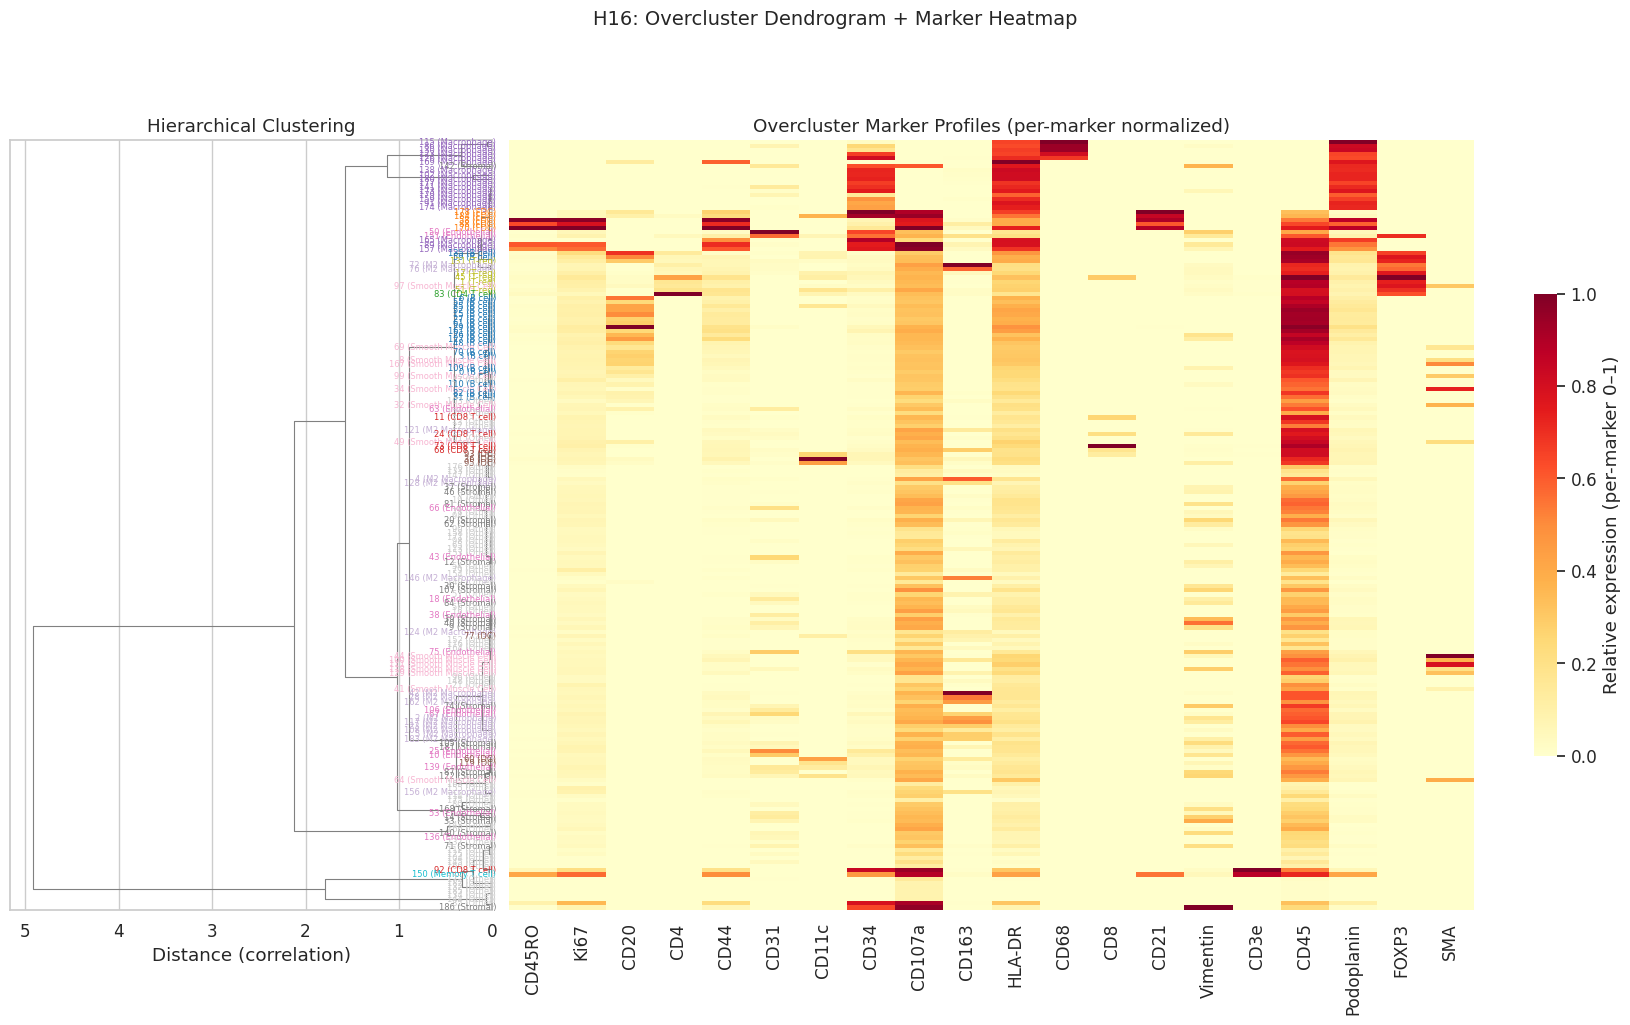

In [15]:
# ── Dendrogram + heatmap visualization for manual review ──
fig = plt.figure(figsize=(22, 10))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.5], wspace=0.02)

# Left: dendrogram
ax_dendro = fig.add_subplot(gs[0])

with plt.rc_context({'lines.linewidth': 0.8}):
    dendro_result = dendrogram(
        Z, orientation='left', ax=ax_dendro,
        no_labels=True, color_threshold=0,
        above_threshold_color='grey',
    )
ax_dendro.set_title("Hierarchical Clustering")
ax_dendro.set_xlabel("Distance (correlation)")

# Reorder cluster medians by dendrogram leaf order
leaf_order = dendro_result["leaves"]
ordered_clusters = [cluster_ids[i] for i in leaf_order]
ordered_medians = cluster_medians.loc[ordered_clusters]

# Right: heatmap of arcsinh medians
ax_hm = fig.add_subplot(gs[1])

# Per-column min-max normalization: each marker scaled to its own [0, 1]
# This prevents cross-marker magnitude comparisons and shows relative
# expression within each marker independently
hm_data = ordered_medians.copy()
for col in hm_data.columns:
    cmin, cmax = hm_data[col].min(), hm_data[col].max()
    if cmax - cmin > 1e-8:
        hm_data[col] = (hm_data[col] - cmin) / (cmax - cmin)
    else:
        hm_data[col] = 0.0

sns.heatmap(hm_data.astype(float), cmap="YlOrRd", vmin=0, vmax=1,
            ax=ax_hm, xticklabels=True,
            yticklabels=[f"{cl} ({overcluster_to_ct[cl]})"
                         for cl in ordered_clusters],
            cbar_kws={"label": "Relative expression (per-marker 0–1)", "shrink": 0.6})
ax_hm.set_title("Overcluster Marker Profiles (per-marker normalized)")
ax_hm.set_xlabel(""); ax_hm.set_ylabel("")
ax_hm.tick_params(axis='y', labelsize=6)

# Color y-tick labels by cell type
for i, label in enumerate(ax_hm.get_yticklabels()):
    cl = ordered_clusters[i]
    ct = overcluster_to_ct[cl]
    label.set_color(ct_palette.get(ct, "black"))

plt.suptitle("H16: Overcluster Dendrogram + Marker Heatmap", fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, "H16_overcluster_dendrogram")
plt.show()

Saved: analysis/figures/H16_signature_scores.png


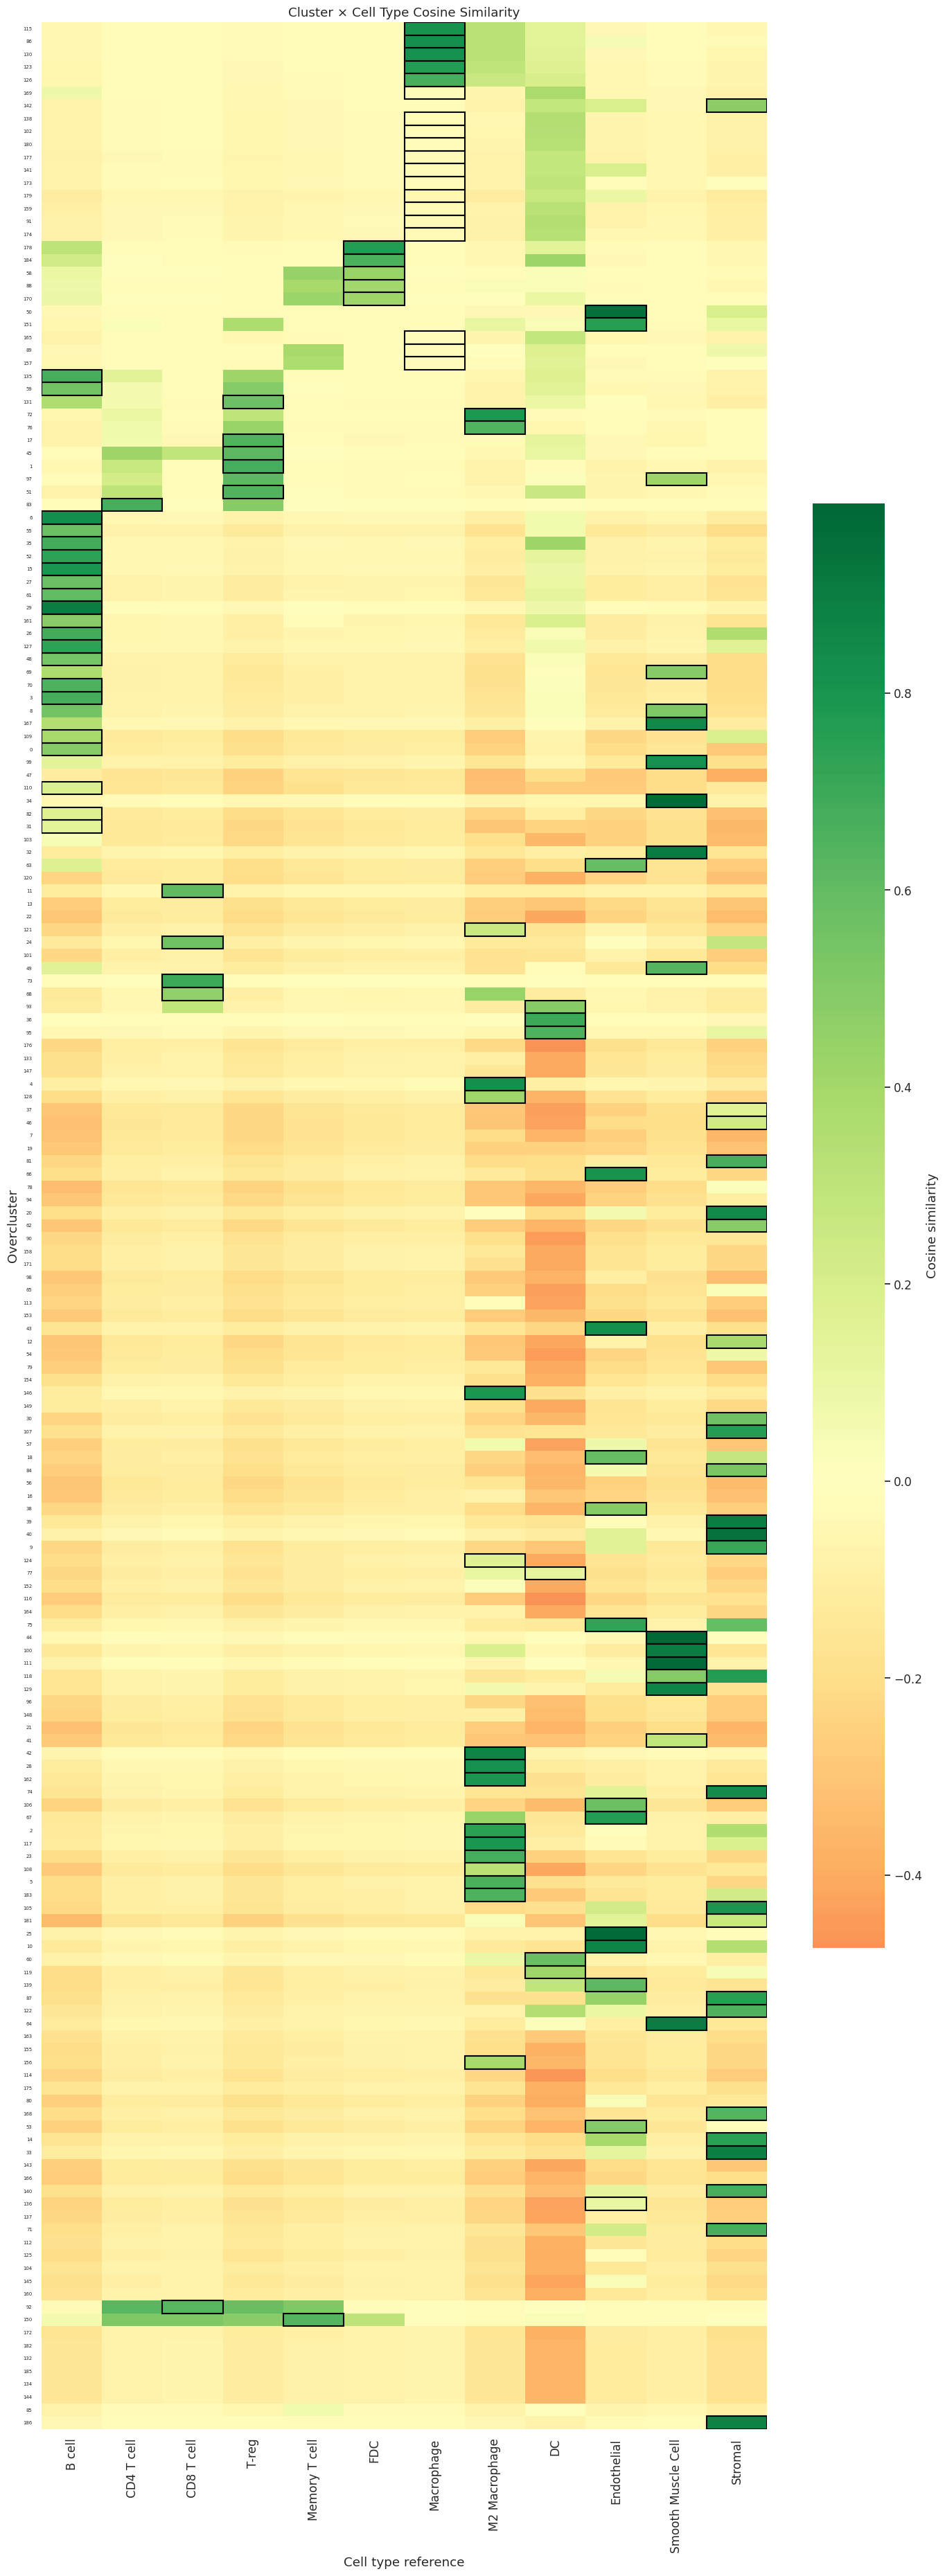

In [16]:
# ── Cosine similarity matrix heatmap ──
fig, ax = plt.subplots(figsize=(14, max(6, len(cluster_ids) * 0.2)))

# Reorder by dendrogram
ordered_sims = sim_matrix.loc[ordered_clusters]

sns.heatmap(ordered_sims.astype(float), cmap="RdYlGn", center=0,
            ax=ax, xticklabels=True,
            yticklabels=[f"{cl}" for cl in ordered_clusters],
            annot=False,
            cbar_kws={"label": "Cosine similarity", "shrink": 0.6})
ax.set_title("Cluster × Cell Type Cosine Similarity")
ax.set_xlabel("Cell type reference"); ax.set_ylabel("Overcluster")
ax.tick_params(axis='y', labelsize=5)

# Highlight the winning cell type for each cluster
for i, cl in enumerate(ordered_clusters):
    best_ct = overcluster_to_ct[cl]
    if best_ct != "Other" and best_ct in CT_NAMES:
        j = CT_NAMES.index(best_ct)
        ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", lw=1.5))

plt.tight_layout()
save_figure(fig, "H16_signature_scores")
plt.show()

In [17]:
# ── MANUAL OVERRIDE POINT ──
# Review the dendrogram + heatmap above. If any overcluster assignments are
# incorrect, override them here. Use the cluster IDs from the mapping table.

MANUAL_OVERRIDES = {
    # Example: "5": "FDC",  # cluster 5 was called "B cell" but CD21 dominates
}

for cl_id, ct in MANUAL_OVERRIDES.items():
    old = overcluster_to_ct[cl_id]
    overcluster_to_ct[cl_id] = ct
    print(f"Override: cluster {cl_id}: {old} → {ct}")

if not MANUAL_OVERRIDES:
    print("No manual overrides applied.")

No manual overrides applied.


In [18]:
# ── Apply cell type labels to all 2.88M cells ──
# overcluster_to_ct was built in Cell 6 (from raw_assignments) and
# optionally modified in Cell 9 (manual overrides)
adata.obs["cell_type"] = adata.obs["leiden_hi"].map(overcluster_to_ct)

# Report
ct_counts = adata.obs["cell_type"].value_counts()
ct_frac = ct_counts / adata.shape[0]
print("Cell type distribution (H16 cluster-based):")
for ct in CELL_TYPE_ORDER:
    if ct in ct_counts.index:
        print(f"  {ct:20s} {ct_counts[ct]:>9,}  ({ct_frac[ct]:5.1%})")

# Also propagate to UMAP subsample
adata_umap_sub.obs["cell_type"] = adata.obs.loc[adata_umap_sub.obs.index, "cell_type"].values

Cell type distribution (H16 cluster-based):
  B cell               3,376,421  (18.6%)
  CD4 T cell              18,755  ( 0.1%)
  CD8 T cell             729,513  ( 4.0%)
  T-reg                  882,712  ( 4.9%)
  Memory T cell            4,762  ( 0.0%)
  FDC                     41,415  ( 0.2%)
  Macrophage              99,082  ( 0.5%)
  M2 Macrophage        2,088,514  (11.5%)
  DC                     448,907  ( 2.5%)
  Endothelial          1,911,189  (10.5%)
  Smooth Muscle Cell   1,425,788  ( 7.9%)
  Stromal              3,043,231  (16.8%)
  Other                4,064,166  (22.4%)


Saved: analysis/figures/H16_celltype_umap_validation.png


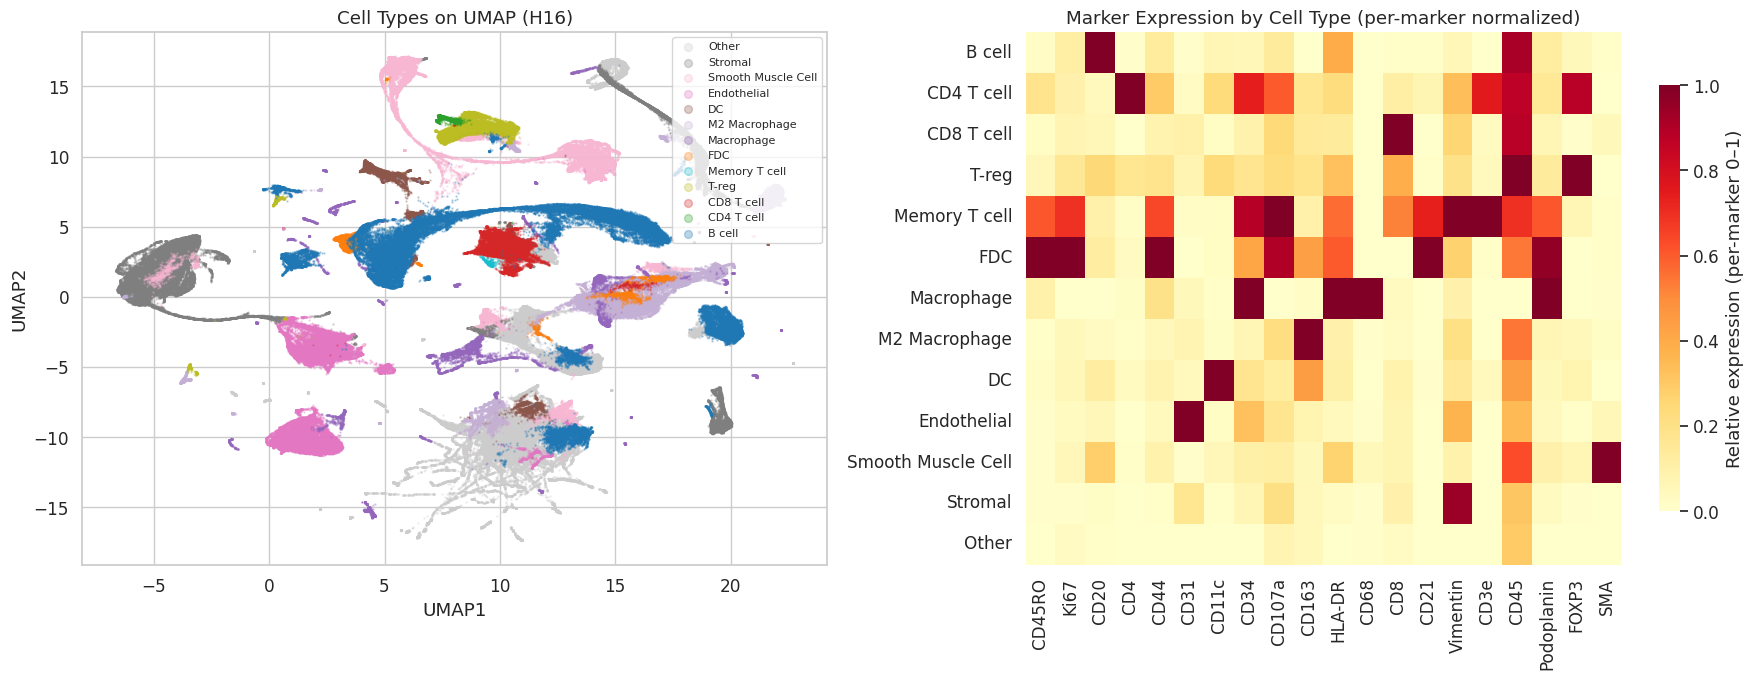


Per-image cell type fractions (flag outliers > 2 SD from mean):


  OUTLIER: HDL073_PC29.ome.tiff                     CD4 T cell           3.3% (mean=0.4%, +2.8 SD)
  OUTLIER: HDL073_PC29.ome.tiff                     CD8 T cell           7.7% (mean=4.1%, +2.0 SD)
  OUTLIER: HDL073_PC29.ome.tiff                     T-reg                9.7% (mean=5.0%, +2.0 SD)
  OUTLIER: HDL073_PC29.ome.tiff                     Memory T cell        1.5% (mean=0.1%, +3.0 SD)
  OUTLIER: HDL073_PC29.ome.tiff                     FDC                  12.3% (mean=1.2%, +3.0 SD)
  OUTLIER: 1901HBMP004_PC29.ome.tiff                Macrophage           33.2% (mean=3.6%, +3.0 SD)
  OUTLIER: HDL073_PC29.ome.tiff                     DC                   10.3% (mean=3.0%, +2.1 SD)
  OUTLIER: 1901HBMP004_PC29.ome.tiff                Smooth Muscle Cell   32.9% (mean=9.0%, +2.7 SD)


Saved: analysis/figures/H16_celltype_umap_by_genotype.png


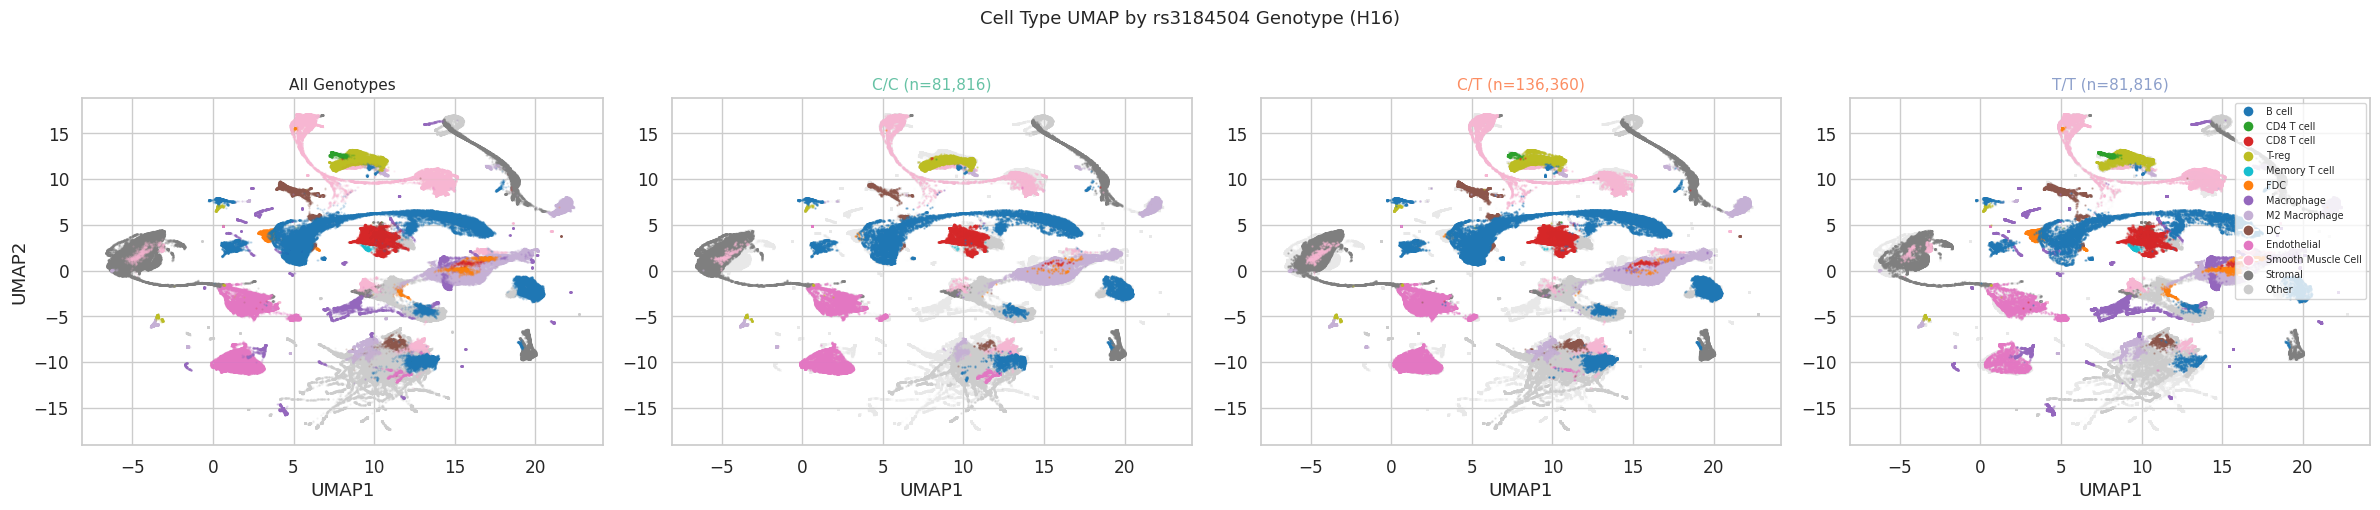

In [19]:
# ── Validation: UMAP + marker heatmap ──
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# UMAP colored by cell type
ax = axes[0]
umap_xy = adata_umap_sub.obsm["X_umap"]
for ct in reversed(CELL_TYPE_ORDER):
    mask = adata_umap_sub.obs["cell_type"].values == ct
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1],
                   c=ct_palette.get(ct, "grey"), s=0.5, alpha=0.3,
                   label=ct, rasterized=True)
ax.legend(markerscale=8, frameon=True, fontsize=8, loc="upper right")
ax.set_title("Cell Types on UMAP (H16)")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

# Marker heatmap by cell type — per-column min-max normalization
# Each marker column scaled to [0, 1] so columns are comparable only
# within themselves, not across markers
ax = axes[1]
present_types = [ct for ct in CELL_TYPE_ORDER if ct in adata.obs["cell_type"].values]
ct_marker_means = pd.DataFrame(index=present_types, columns=CLUSTERING_MARKERS, dtype=float)
arcsinh_data = np.asarray(adata.layers["arcsinh"])
for ct in present_types:
    mask = adata.obs["cell_type"].values == ct
    ct_marker_means.loc[ct] = np.mean(arcsinh_data[mask], axis=0)

# Per-column min-max
hm_ct = ct_marker_means.copy()
for col in hm_ct.columns:
    cmin, cmax = hm_ct[col].min(), hm_ct[col].max()
    if cmax - cmin > 1e-8:
        hm_ct[col] = (hm_ct[col] - cmin) / (cmax - cmin)
    else:
        hm_ct[col] = 0.0

sns.heatmap(hm_ct.astype(float), cmap="YlOrRd", vmin=0, vmax=1,
            ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "Relative expression (per-marker 0–1)", "shrink": 0.8})
ax.set_title("Marker Expression by Cell Type (per-marker normalized)")
ax.set_xlabel("")

plt.tight_layout()
save_figure(fig, "H16_celltype_umap_validation")
plt.show()

# ── Per-image cell type fraction — flag outliers ──
print("\nPer-image cell type fractions (flag outliers > 2 SD from mean):")
img_ct = adata.obs.groupby(["Image", "cell_type"], observed=True).size().unstack(fill_value=0)
img_ct_frac = img_ct.div(img_ct.sum(axis=1), axis=0)
for ct in [c for c in CELL_TYPE_ORDER if c in img_ct_frac.columns and c != "Other"]:
    col = img_ct_frac[ct]
    mu, sd = col.mean(), col.std()
    outliers = col[col > mu + 2 * sd]
    if len(outliers):
        for img, val in outliers.items():
            print(f"  OUTLIER: {img:40s} {ct:20s} {val:.1%} (mean={mu:.1%}, +{(val-mu)/sd:.1f} SD)")

# ── Per-genotype UMAP ──
adata_umap_sub.obs["Genotype"] = adata.obs.loc[adata_umap_sub.obs.index, "Genotype"].values

genotypes = [g for g in GENO_ORDER if g in adata_umap_sub.obs["Genotype"].values]
fig, axes = plt.subplots(1, len(genotypes) + 1, figsize=(6 * (len(genotypes) + 1), 5))

ax = axes[0]
for ct in reversed(CELL_TYPE_ORDER):
    mask = adata_umap_sub.obs["cell_type"].values == ct
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1],
                   c=ct_palette.get(ct, "grey"), s=0.3, alpha=0.2,
                   rasterized=True)
ax.set_title("All Genotypes", fontsize=11)
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

for i, geno in enumerate(genotypes):
    ax = axes[i + 1]
    geno_mask = adata_umap_sub.obs["Genotype"].values == geno
    n_geno = geno_mask.sum()
    ax.scatter(umap_xy[~geno_mask, 0], umap_xy[~geno_mask, 1],
               c="#e8e8e8", s=0.1, alpha=0.1, rasterized=True)
    for ct in reversed(CELL_TYPE_ORDER):
        ct_mask = geno_mask & (adata_umap_sub.obs["cell_type"].values == ct)
        if ct_mask.any():
            ax.scatter(umap_xy[ct_mask, 0], umap_xy[ct_mask, 1],
                       c=ct_palette.get(ct, "grey"), s=0.5, alpha=0.4,
                       label=ct, rasterized=True)
    ax.set_title(f"{geno} (n={n_geno:,})", fontsize=11,
                 color=GENO_PALETTE.get(geno, "black"))
    ax.set_xlabel("UMAP1"); ax.set_ylabel("")

handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=ct_palette[ct],
           markersize=8, label=ct) for ct in CELL_TYPE_ORDER if ct in adata_umap_sub.obs["cell_type"].values]
axes[-1].legend(handles=handles, fontsize=7, loc="upper right", frameon=True)

plt.suptitle("Cell Type UMAP by rs3184504 Genotype (H16)", fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H16_celltype_umap_by_genotype")
plt.show()

In [20]:
# ── Biological sanity check ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()

# B cells should dominate Follicle, T cells PALS, Macrophages RedPulp
for region in ["Follicle", "PALS", "RedPulp"]:
    reg_cells = obs_geno[obs_geno["Region"] == region]
    if len(reg_cells) == 0:
        continue
    top_ct = reg_cells["cell_type"].value_counts(normalize=True).head(3)
    print(f"\n{region} — top cell types:")
    for ct, frac in top_ct.items():
        print(f"  {ct:20s} {frac:5.1%}")

# Inter-sample CV for key cell types
print("\nInter-sample coefficient of variation:")
ct_per_sample = obs_geno.groupby(["Sample", "cell_type"], observed=True).size().unstack(fill_value=0)
ct_per_sample = ct_per_sample.div(ct_per_sample.sum(axis=1), axis=0)
for ct in ["B cell", "CD4 T cell", "CD8 T cell", "Macrophage", "Stromal", "Endothelial"]:
    if ct in ct_per_sample.columns:
        cv = ct_per_sample[ct].std() / (ct_per_sample[ct].mean() + 1e-8)
        print(f"  {ct:20s} CV={cv:.2f}")


Follicle — top cell types:
  B cell               79.6%
  Smooth Muscle Cell    6.6%
  T-reg                 3.9%



PALS — top cell types:
  Smooth Muscle Cell   35.1%
  T-reg                24.7%
  B cell               12.9%



RedPulp — top cell types:
  Other                29.1%
  Stromal              21.4%
  M2 Macrophage        14.9%

Inter-sample coefficient of variation:


  B cell               CV=0.33
  CD4 T cell           CV=2.46
  CD8 T cell           CV=0.44
  Macrophage           CV=2.79
  Stromal              CV=0.34
  Endothelial          CV=0.37


---
## Genotype Analysis
Per-image cell-type proportions tested across rs3184504 genotype groups.

In [21]:
# ── Per-image cell type proportions ──
has_geno = adata.obs["Genotype"].notna()
obs_geno = adata.obs[has_geno].copy()
print(f"Cells with genotype: {has_geno.sum():,} / {adata.shape[0]:,}")
print(f"Samples: {sorted(obs_geno['Sample'].unique())}")

ct_counts = obs_geno.groupby(["Sample", "cell_type"], observed=True).size().reset_index(name="Count")
total_per_sample = obs_geno.groupby("Sample", observed=True).size().reset_index(name="Total")
ct_counts = ct_counts.merge(total_per_sample, on="Sample")
ct_counts["Proportion"] = ct_counts["Count"] / ct_counts["Total"]

prop_wide = ct_counts.pivot(index="Sample", columns="cell_type", values="Proportion").fillna(0)
sample_meta = obs_geno.drop_duplicates("Sample").set_index("Sample")[["Genotype", "Platform"]]
prop_wide = prop_wide.join(sample_meta)

save_table(prop_wide.reset_index(), "H16_cell_type_proportions")
print(f"\nProportion table: {prop_wide.shape[0]} samples x {prop_wide.shape[1] - 2} cell types")
prop_wide.head()

Cells with genotype: 18,134,455 / 18,134,455
Samples: ['1901HBMP004', 'HDL011', 'HDL043', 'HDL052', 'HDL053', 'HDL055', 'HDL063', 'HDL070', 'HDL073', 'HDL079', 'HDL086']


Saved: analysis/tables/H16_cell_type_proportions.csv

Proportion table: 11 samples x 13 cell types


,B cell,CD4 T cell,CD8 T cell,DC,Endothelial,FDC,M2 Macrophage,Macrophage,Memory T cell,Other,Smooth Muscle Cell,Stromal,T-reg,Genotype,Platform
Sample,,,,,,,,,,,,,,,
1901HBMP004,0.052202,0.000000,0.009469,0.000105,0.063959,0.001223,0.079151,0.331761,0.000021,0.070139,0.329435,0.061994,0.000540,T/T,CODEX
HDL011,0.152243,0.000003,0.060987,0.000186,0.157018,0.001034,0.128095,0.000135,0.000190,0.213181,0.002556,0.216157,0.068216,C/C,Phenocycler
HDL043,0.221664,0.000023,0.054257,0.035483,0.127362,0.000294,0.055481,0.000180,0.000062,0.242848,0.075943,0.140962,0.045441,C/T,Phenocycler
HDL052,0.096745,0.013305,0.032939,0.024774,0.145871,0.000494,0.136546,0.002214,0.000085,0.287380,0.035675,0.181377,0.042596,C/T,Phenocycler
HDL053,0.221730,0.000000,0.031403,0.000170,0.068568,0.000360,0.101347,0.000479,0.000030,0.235758,0.117035,0.180631,0.042490,C/C,Phenocycler


Saved: analysis/figures/H16_celltype_stacked_bar.png


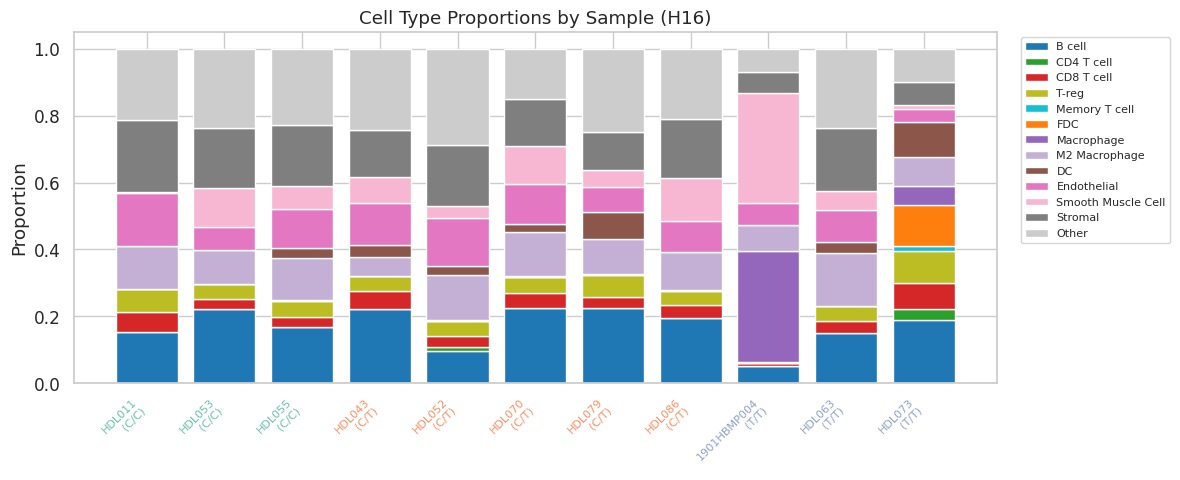

In [22]:
# ── Stacked bar chart of proportions by genotype ──
plot_types = [ct for ct in CELL_TYPE_ORDER if ct in prop_wide.columns and ct != "Other"]
order = prop_wide.sort_values("Genotype").index

fig, ax = plt.subplots(figsize=(12, 5))
bottom = np.zeros(len(order))
for ct in plot_types:
    vals = prop_wide.loc[order, ct].values
    ax.bar(range(len(order)), vals, bottom=bottom, label=ct,
           color=ct_palette.get(ct, "grey"), width=0.8)
    bottom += vals

if "Other" in prop_wide.columns:
    vals = prop_wide.loc[order, "Other"].values
    ax.bar(range(len(order)), vals, bottom=bottom, label="Other",
           color=ct_palette["Other"], width=0.8)

ax.set_xticks(range(len(order)))
labels = []
for s in order:
    g = str(prop_wide.loc[s, "Genotype"])
    labels.append(f"{s}\n({g})")
ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
for i, s in enumerate(order):
    g = str(prop_wide.loc[s, "Genotype"])
    ax.get_xticklabels()[i].set_color(GENO_PALETTE.get(g, "black"))

ax.set_ylabel("Proportion")
ax.set_title("Cell Type Proportions by Sample (H16)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
save_figure(fig, "H16_celltype_stacked_bar")
plt.show()

Saved: analysis/figures/H16_celltype_genotype_boxplots.png


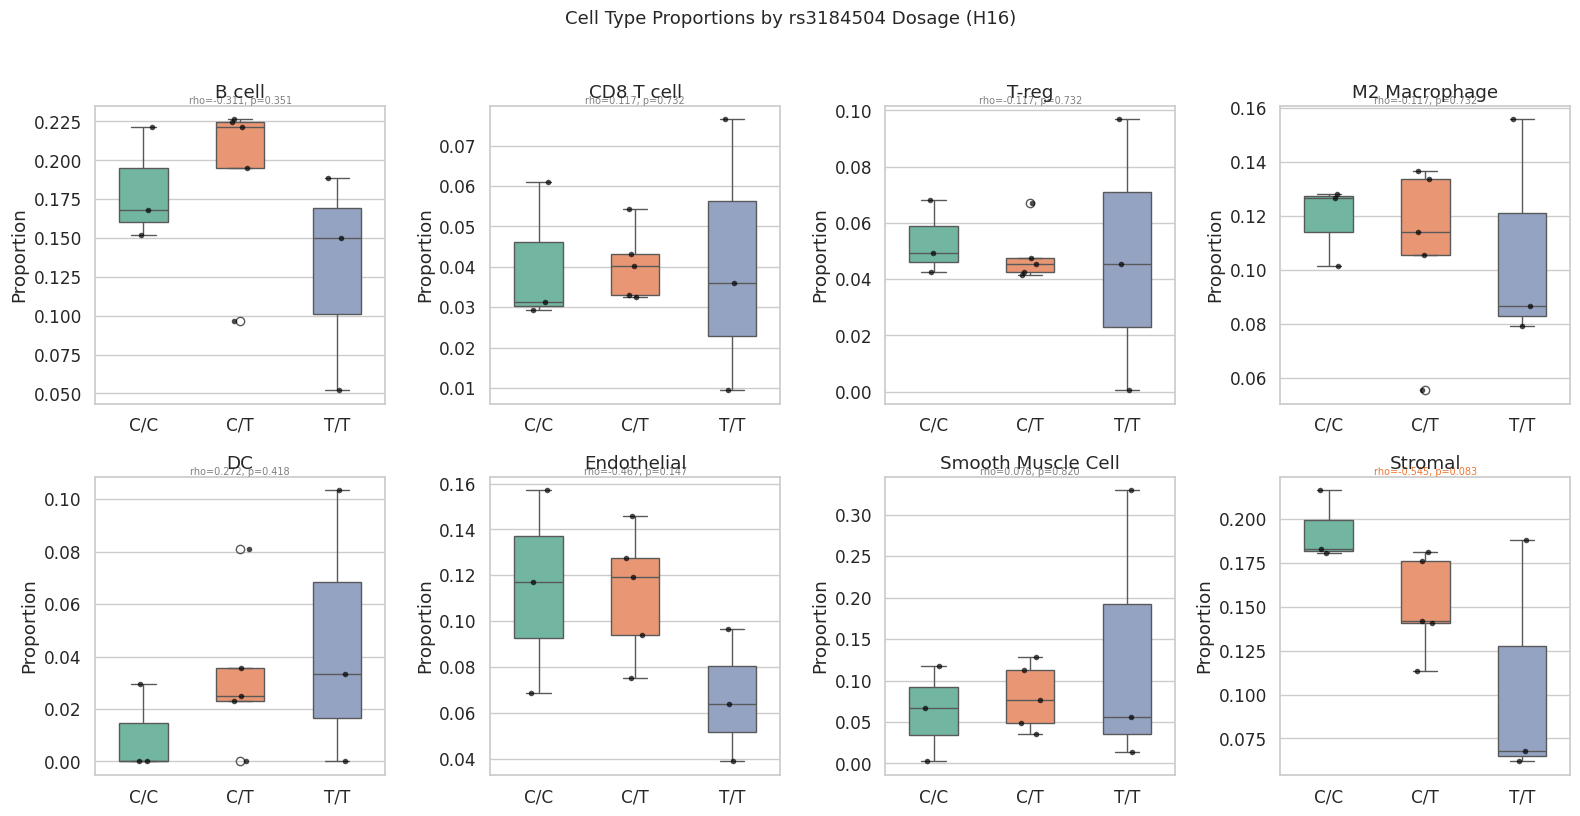

Saved: analysis/tables/H16_celltype_genotype_stats.csv

Dosage consistency warnings:
  Stromal: C/C vs C/T sig but C/C vs T/T not — dosage-inconsistent

Significant results (p < 0.1):
                     Test  Metric  Statistic        p Effect_Size Dosage_Consistent
Mann-Whitney (C/C vs C/T) Stromal  14.000000 0.071429    r=-0.867                No
          Spearman dosage Stromal  -0.544949 0.082993  rho=-0.545                No


In [23]:
# ── Cell type proportion boxplots by genotype + dosage trend ──
major_types = [ct for ct in CELL_TYPE_ORDER
               if ct in prop_wide.columns and ct != "Other"
               and prop_wide[ct].median() > 0.01]

n_types = len(major_types)
ncols = min(4, n_types)
nrows = (n_types + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

all_stats = []
for i, ct in enumerate(major_types):
    ax = axes[i // ncols, i % ncols]
    plot_df = prop_wide[[ct, "Genotype"]].copy()
    plot_df["Genotype"] = plot_df["Genotype"].astype(str)

    sns.boxplot(data=plot_df, x="Genotype", y=ct, order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=plot_df, x="Genotype", y=ct, order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(ct)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion")

    stats = full_stats_table(prop_wide.assign(Genotype=prop_wide["Genotype"].astype(str)),
                             ct, label=ct)
    all_stats.append(stats)
    _annotate_dosage(ax, stats)

for j in range(n_types, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Cell Type Proportions by rs3184504 Dosage (H16)",
             fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H16_celltype_genotype_boxplots")
plt.show()

stats_df = pd.concat(all_stats, ignore_index=True)
stats_df = add_dosage_consistency_column(stats_df)
save_table(stats_df, "H16_celltype_genotype_stats")

# Print dosage consistency warnings
dc_flags = flag_dosage_inconsistent(stats_df)
if dc_flags:
    print("\nDosage consistency warnings:")
    for f in dc_flags:
        print(f"  {f}")

print("\nSignificant results (p < 0.1):")
sig = stats_df[stats_df["p"] < 0.1]
if len(sig):
    print(sig.to_string(index=False))
else:
    print("  None")

In [24]:
# ── Platform diagnostic ──
ct_cols = [ct for ct in CELL_TYPE_ORDER if ct in prop_wide.columns]
plat_df = prop_wide[ct_cols + ["Platform"]].copy()
plat_results = platform_diagnostic(plat_df, ct_cols)
save_table(plat_results, "H16_platform_diagnostic")

print("Platform diagnostic (CODEX vs Phenocycler):")
for _, row in plat_results.iterrows():
    flag = " ***" if row["p"] < 0.1 else ""
    print(f"  {row['Feature']:20s} p={row['p']:.4f}  r={row['rank_biserial']:.3f}{flag}")

confounded = plat_results[plat_results["p"] < 0.1]["Feature"].tolist()
if confounded:
    print(f"\nWARNING: Platform-confounded cell types: {confounded}")
else:
    print("\nNo significant platform effects detected.")

Saved: analysis/tables/H16_platform_diagnostic.csv
Platform diagnostic (CODEX vs Phenocycler):
  B cell               p=0.3273  r=0.556
  CD4 T cell           p=1.0000  r=-0.056
  CD8 T cell           p=1.0000  r=0.000
  T-reg                p=1.0000  r=0.000
  Memory T cell        p=1.0000  r=0.000
  FDC                  p=0.2182  r=-0.667
  Macrophage           p=0.0364  r=-1.000 ***
  M2 Macrophage        p=0.1455  r=0.778
  DC                   p=0.9091  r=-0.111
  Endothelial          p=0.0364  r=1.000 ***
  Smooth Muscle Cell   p=0.9091  r=-0.111
  Stromal              p=0.0364  r=1.000 ***
  Other                p=0.0364  r=1.000 ***



---
## Regional Cell Type Analysis
Cell type composition varies by tissue region. Test genotype effects within each region.

Saved: analysis/figures/H16_region_celltype_heatmap.png


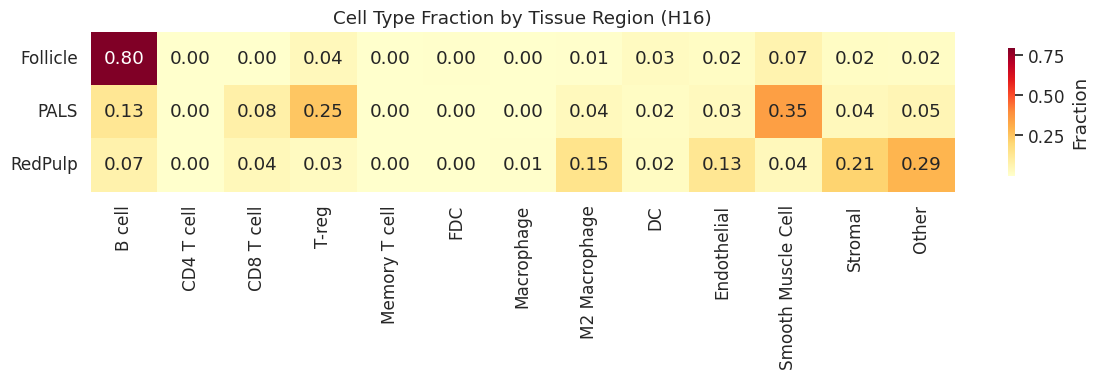


Region-specific genotype tests:


Saved: analysis/tables/H16_region_celltype_genotype_stats.csv

Dosage consistency warnings:
  PALS:M2 Macrophage: C/C vs C/T sig but C/C vs T/T not — dosage-inconsistent
  RedPulp:Endothelial: C/T vs T/T sig but C/C vs T/T not — dosage-inconsistent
  RedPulp:Stromal: C/C vs C/T sig but C/C vs T/T not — dosage-inconsistent
                     Test              Metric        p Effect_Size
           Kruskal-Wallis  PALS:M2 Macrophage 0.047144            
Mann-Whitney (C/C vs C/T)  PALS:M2 Macrophage 0.035714    r=-1.000
          Spearman dosage  PALS:M2 Macrophage 0.059300  rho=-0.584
          Spearman dosage             PALS:DC 0.053315   rho=0.625
          Spearman dosage    PALS:Endothelial 0.082993  rho=-0.545
          Spearman dosage        PALS:Stromal 0.059300  rho=-0.584
Mann-Whitney (C/T vs T/T) RedPulp:Endothelial 0.071429    r=-0.867
           Kruskal-Wallis     RedPulp:Stromal 0.096386            
Mann-Whitney (C/C vs C/T)     RedPulp:Stromal 0.071429    r=-0.867
      

In [25]:
# ── Cell type by region heatmap + region-specific genotype tests ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()
region_ct = obs_geno.groupby(["Region", "cell_type"], observed=True).size().reset_index(name="n")
region_total = obs_geno.groupby("Region", observed=True).size().reset_index(name="total")
region_ct = region_ct.merge(region_total, on="Region")
region_ct["frac"] = region_ct["n"] / region_ct["total"]

hm_data = region_ct.pivot(index="Region", columns="cell_type", values="frac").fillna(0)
region_order = [r for r in ["Follicle", "PALS", "RedPulp", "Other"] if r in hm_data.index]
ct_order = [ct for ct in CELL_TYPE_ORDER if ct in hm_data.columns]
hm_data = hm_data.loc[region_order, ct_order]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(hm_data, cmap="YlOrRd", annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "Fraction", "shrink": 0.8})
ax.set_title("Cell Type Fraction by Tissue Region (H16)")
ax.set_ylabel(""); ax.set_xlabel("")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va="center")
plt.tight_layout()
save_figure(fig, "H16_region_celltype_heatmap")
plt.show()

# Region-specific genotype tests
print("\nRegion-specific genotype tests:")
region_stats = []
for region in ["Follicle", "PALS", "RedPulp"]:
    reg_cells = obs_geno[obs_geno["Region"] == region]
    reg_ct = reg_cells.groupby(["Sample", "cell_type"], observed=True).size().reset_index(name="n")
    reg_total = reg_cells.groupby("Sample", observed=True).size().reset_index(name="total")
    reg_ct = reg_ct.merge(reg_total, on="Sample")
    reg_ct["Proportion"] = reg_ct["n"] / reg_ct["total"]
    reg_ct["Genotype"] = reg_ct["Sample"].map(GENOTYPE_MAP)

    for ct in major_types:
        ct_data = reg_ct[reg_ct["cell_type"] == ct]
        if len(ct_data) < 3:
            continue
        stats = full_stats_table(ct_data, "Proportion", label=f"{region}:{ct}")
        region_stats.append(stats)

if region_stats:
    region_stats_df = pd.concat(region_stats, ignore_index=True)
    region_stats_df = add_dosage_consistency_column(region_stats_df)
    save_table(region_stats_df, "H16_region_celltype_genotype_stats")

    dc_flags = flag_dosage_inconsistent(region_stats_df)
    if dc_flags:
        print("\nDosage consistency warnings:")
        for f in dc_flags:
            print(f"  {f}")

    sig = region_stats_df[region_stats_df["p"] < 0.1]
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  No significant results at p < 0.1")
else:
    print("  Insufficient data for region-specific tests")

---
## Distance Analysis
Mean signed distance from each cell type to tissue structures, by genotype.

Saved: analysis/tables/H16_celltype_distances.csv
Distance records: 411


Saved: analysis/figures/H16_distance_heatmap.png


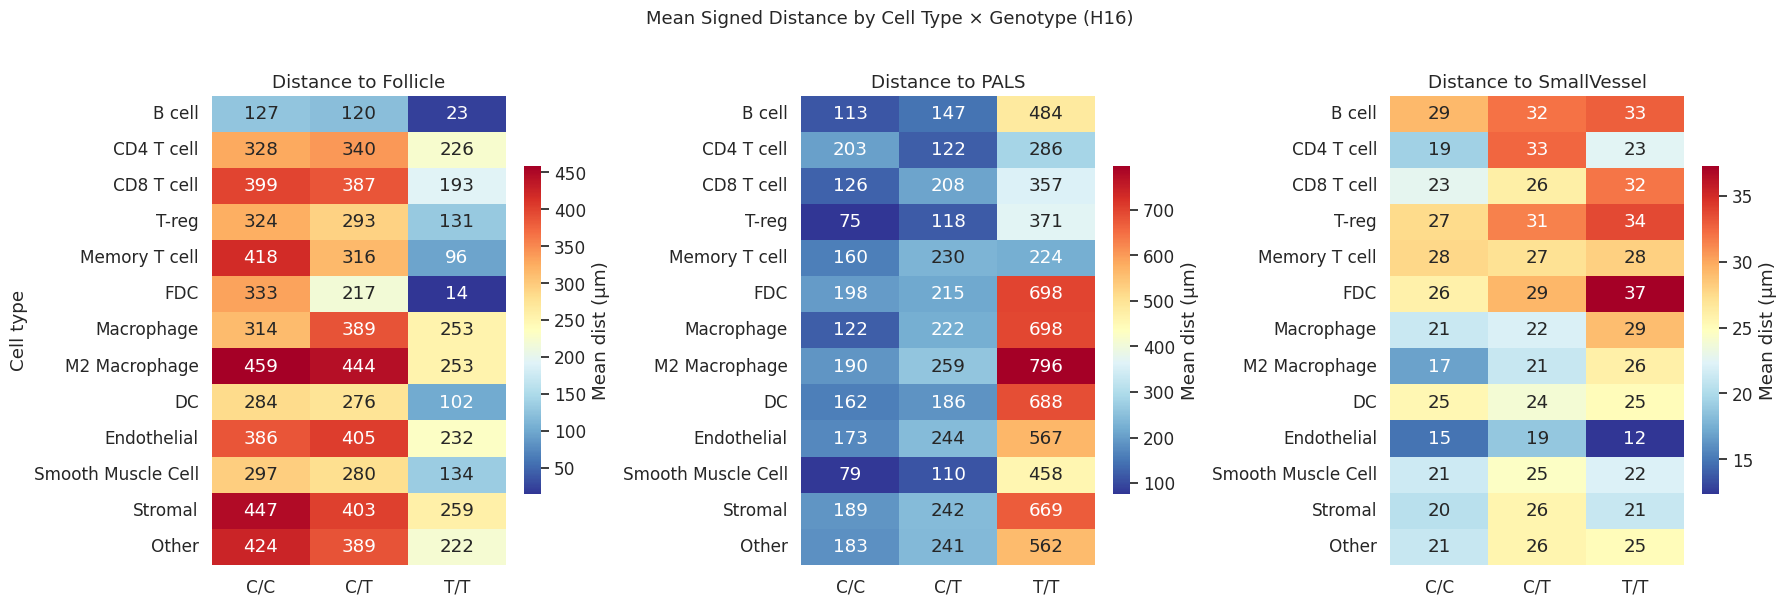

In [26]:
# ── Mean signed distance by cell type and genotype ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()

structures = ["Follicle", "PALS", "SmallVessel"]
# Follicle and PALS are measured against the region layer, so they agree with
# the Region labels. SmallVessel keeps QuPath's column: the region layer holds
# no vessel polygons, by design — vessels come from the annotation CSV instead.
dist_col_map = {"Follicle": "dist_Follicle_um",
                "PALS": "dist_PALS_um",
                "SmallVessel": "Signed distance to annotation SmallVessel \u00b5m"}

dist_records = []
for sample in obs_geno["Sample"].unique():
    s_data = obs_geno[obs_geno["Sample"] == sample]
    geno = s_data["Genotype"].iloc[0]
    for ct in CELL_TYPE_ORDER:
        ct_data = s_data[s_data["cell_type"] == ct]
        if len(ct_data) < 10:
            continue
        for struct, dcol in dist_col_map.items():
            vals = ct_data[dcol].values
            dist_records.append({
                "Sample": sample, "Genotype": geno,
                "cell_type": ct, "Structure": struct,
                "mean_dist": np.mean(vals),
                "median_dist": np.median(vals),
                "frac_inside": np.mean(vals < 0),
                "n_cells": len(vals),
            })

dist_df = pd.DataFrame(dist_records)
save_table(dist_df, "H16_celltype_distances")
print(f"Distance records: {len(dist_df):,}")

fig, axes = plt.subplots(1, len(structures), figsize=(6 * len(structures), 6))
for j, struct in enumerate(structures):
    ax = axes[j]
    sub = dist_df[dist_df["Structure"] == struct]
    pivot = sub.pivot_table(index="cell_type", columns="Genotype",
                            values="mean_dist", aggfunc="mean")
    pivot = pivot.reindex(index=[ct for ct in CELL_TYPE_ORDER if ct in pivot.index],
                          columns=GENO_ORDER)
    sns.heatmap(pivot, cmap="RdYlBu_r", annot=True, fmt=".0f", ax=ax,
                cbar_kws={"label": "Mean dist (\u00b5m)", "shrink": 0.7})
    ax.set_title(f"Distance to {struct}")
    ax.set_ylabel("" if j > 0 else "Cell type")
    ax.set_xlabel("")

plt.suptitle("Mean Signed Distance by Cell Type \u00d7 Genotype (H16)", fontsize=13, y=1.01)
plt.tight_layout()
save_figure(fig, "H16_distance_heatmap")
plt.show()

In [27]:
# ── Distance stats — genotype tests on key cell type × structure pairs ──
KEY_PAIRS = [
    ("B cell",      "Follicle"),
    ("CD4 T cell",  "PALS"),
    ("CD8 T cell",  "PALS"),
    ("Macrophage",  "SmallVessel"),
    ("Endothelial", "SmallVessel"),
    ("T-reg",       "Follicle"),
]
all_dist_stats = []
for ct, struct in KEY_PAIRS:
    sub = dist_df[(dist_df["cell_type"] == ct) & (dist_df["Structure"] == struct)]
    if len(sub) < 3:
        print(f"  {ct} x {struct}: insufficient data")
        continue
    stats_mean = full_stats_table(sub, "mean_dist", label=f"{ct}-{struct} mean_dist")
    all_dist_stats.append(stats_mean)
    stats_frac = full_stats_table(sub, "frac_inside", label=f"{ct}-{struct} frac_inside")
    all_dist_stats.append(stats_frac)

if all_dist_stats:
    dist_stats_df = pd.concat(all_dist_stats, ignore_index=True)
    dist_stats_df = add_dosage_consistency_column(dist_stats_df)
    save_table(dist_stats_df, "H16_distance_genotype_stats")

    dc_flags = flag_dosage_inconsistent(dist_stats_df)
    if dc_flags:
        print("\nDosage consistency warnings:")
        for f in dc_flags:
            print(f"  {f}")

    print("\nSignificant results (p < 0.1):")
    sig = dist_stats_df[dist_stats_df["p"] < 0.1]
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")
else:
    print("  No distance tests computed")

Saved: analysis/tables/H16_distance_genotype_stats.csv

Significant results (p < 0.1):
           Test                    Metric        p Effect_Size
Spearman dosage CD8 T cell-PALS mean_dist 0.082993   rho=0.545


---
## Spatial Neighborhood Analysis
k-NN neighborhoods (k=20) characterize local cell-type composition around each cell type.

In [28]:
# ── Compute spatial k-NN neighborhoods per image (parallelized) ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()
obs_geno["_idx"] = np.arange(len(obs_geno))

present_types = sorted(obs_geno["cell_type"].unique())
type_to_int = {ct: i for i, ct in enumerate(present_types)}
n_types = len(present_types)

def process_image_neighbors(image, obs_geno, type_to_int, k):
    """Compute neighborhood composition for one image."""
    img_data = obs_geno[obs_geno["Image"] == image]
    if len(img_data) < k + 1:
        return []

    sample = img_data["Sample"].iloc[0]
    geno = img_data["Genotype"].iloc[0]
    coords = img_data[[X_COL, Y_COL]].values
    types_int = img_data["cell_type"].map(type_to_int).values

    tree = cKDTree(coords)
    _, indices = tree.query(coords, k=k + 1)
    neighbor_idx = indices[:, 1:]

    neighbor_types = types_int[neighbor_idx]
    records = []
    for ct_name, ct_int in type_to_int.items():
        ct_mask = types_int == ct_int
        if ct_mask.sum() < 10:
            continue
        ct_neighbors = neighbor_types[ct_mask]
        for nb_name, nb_int in type_to_int.items():
            frac = (ct_neighbors == nb_int).mean()
            records.append({
                "Image": image, "Sample": sample, "Genotype": geno,
                "cell_type": ct_name, "neighbor_type": nb_name,
                "frac": frac,
            })
    return records

results = Parallel(n_jobs=-1, verbose=1)(
    delayed(process_image_neighbors)(img, obs_geno, type_to_int, SPATIAL_K)
    for img in obs_geno["Image"].unique()
)
neigh_records = [r for batch in results for r in batch]

neigh_df = pd.DataFrame(neigh_records)
save_table(neigh_df, "H16_neighborhood_composition")
print(f"Neighborhood records: {len(neigh_df):,}")
print(f"Images: {neigh_df['Image'].nunique()}, cell types: {neigh_df['cell_type'].nunique()}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=-1)]: Done   8 out of  11 | elapsed:  2.7min remaining:   59.9s


[Parallel(n_jobs=-1)]: Done  11 out of  11 | elapsed:  3.3min finished


Saved: analysis/tables/H16_neighborhood_composition.csv
Neighborhood records: 1,781
Images: 11, cell types: 13


Saved: analysis/figures/H16_neighborhood_enrichment.png


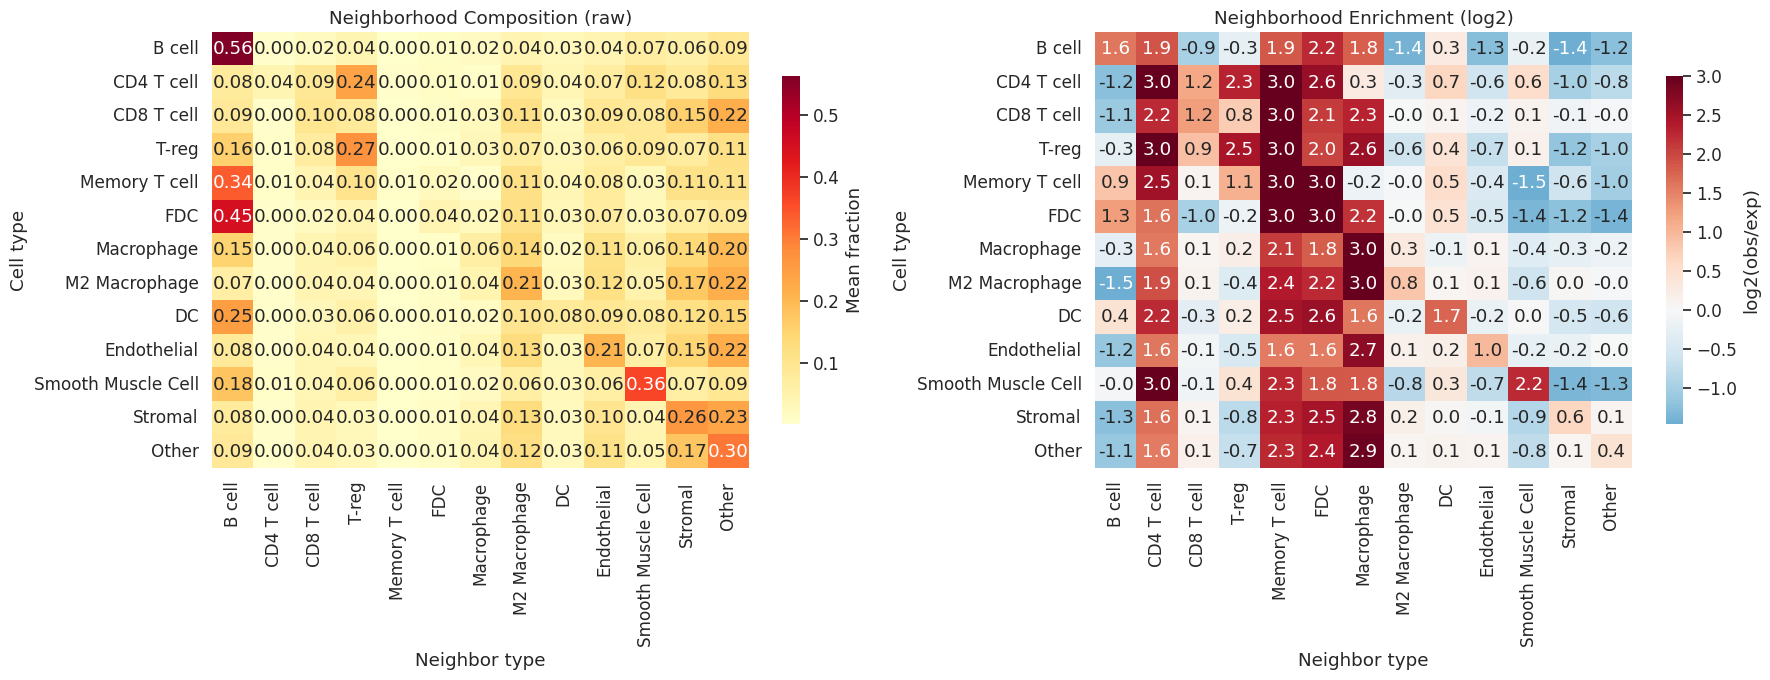

In [29]:
# ── Neighborhood enrichment heatmap ──
mean_comp = neigh_df.groupby(["cell_type", "neighbor_type"], observed=True)["frac"].mean()
mean_comp = mean_comp.unstack(fill_value=0)

all_types = obs_geno["cell_type"].value_counts(normalize=True)
expected = all_types.reindex(mean_comp.columns, fill_value=1e-6)
enrichment = np.log2(mean_comp / expected)
enrichment = enrichment.clip(-3, 3)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ct_order = [ct for ct in CELL_TYPE_ORDER if ct in mean_comp.index]
nb_order = [ct for ct in CELL_TYPE_ORDER if ct in mean_comp.columns]

sns.heatmap(mean_comp.loc[ct_order, nb_order], cmap="YlOrRd", annot=True, fmt=".2f",
            ax=axes[0], cbar_kws={"label": "Mean fraction", "shrink": 0.8})
axes[0].set_title("Neighborhood Composition (raw)")
axes[0].set_xlabel("Neighbor type"); axes[0].set_ylabel("Cell type")

sns.heatmap(enrichment.loc[ct_order, nb_order], cmap="RdBu_r", center=0,
            annot=True, fmt=".1f", ax=axes[1],
            cbar_kws={"label": "log2(obs/exp)", "shrink": 0.8})
axes[1].set_title("Neighborhood Enrichment (log2)")
axes[1].set_xlabel("Neighbor type"); axes[1].set_ylabel("Cell type")

plt.tight_layout()
save_figure(fig, "H16_neighborhood_enrichment")
plt.show()

Saved: analysis/figures/H16_neighborhood_genotype_boxplots.png


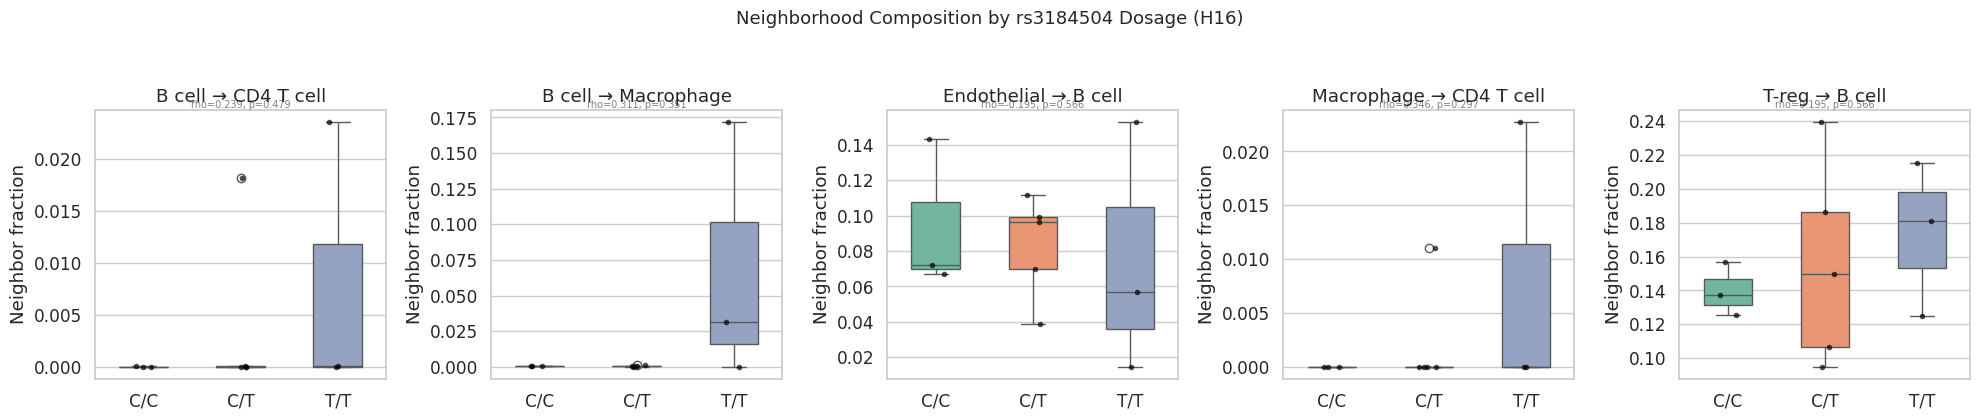

Saved: analysis/tables/H16_neighborhood_genotype_stats.csv

Significant results (p < 0.1):
  None


In [30]:
# ── Neighborhood composition by genotype — key pairs ──
NEIGH_KEY_PAIRS = [
    ("B cell",      "CD4 T cell"),
    ("B cell",      "Macrophage"),
    ("Endothelial", "B cell"),
    ("Macrophage",  "CD4 T cell"),
    ("T-reg",       "B cell"),
]
n_pairs = len(NEIGH_KEY_PAIRS)
fig, axes = plt.subplots(1, n_pairs, figsize=(4 * n_pairs, 4), squeeze=False)
neigh_stats = []
for i, (ct, nb) in enumerate(NEIGH_KEY_PAIRS):
    ax = axes[0, i]
    sub = neigh_df[(neigh_df["cell_type"] == ct) & (neigh_df["neighbor_type"] == nb)].copy()
    if len(sub) < 3:
        ax.set_title(f"{ct}\u2192{nb}\n(no data)")
        continue
    sub["Genotype"] = sub["Genotype"].astype(str)
    sns.boxplot(data=sub, x="Genotype", y="frac", order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=sub, x="Genotype", y="frac", order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(f"{ct} \u2192 {nb}")
    ax.set_xlabel(""); ax.set_ylabel("Neighbor fraction")
    stats = full_stats_table(sub, "frac", label=f"{ct}\u2192{nb}")
    neigh_stats.append(stats)
    _annotate_dosage(ax, stats)
plt.suptitle("Neighborhood Composition by rs3184504 Dosage (H16)", fontsize=13, y=1.05)
plt.tight_layout()
save_figure(fig, "H16_neighborhood_genotype_boxplots")
plt.show()
if neigh_stats:
    neigh_stats_df = pd.concat(neigh_stats, ignore_index=True)
    neigh_stats_df = add_dosage_consistency_column(neigh_stats_df)
    save_table(neigh_stats_df, "H16_neighborhood_genotype_stats")

    dc_flags = flag_dosage_inconsistent(neigh_stats_df)
    if dc_flags:
        print("\nDosage consistency warnings:")
        for f in dc_flags:
            print(f"  {f}")

    sig = neigh_stats_df[neigh_stats_df["p"] < 0.1]
    print("\nSignificant results (p < 0.1):")
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")

Saved: analysis/figures/H16_neighborhood_diversity.png


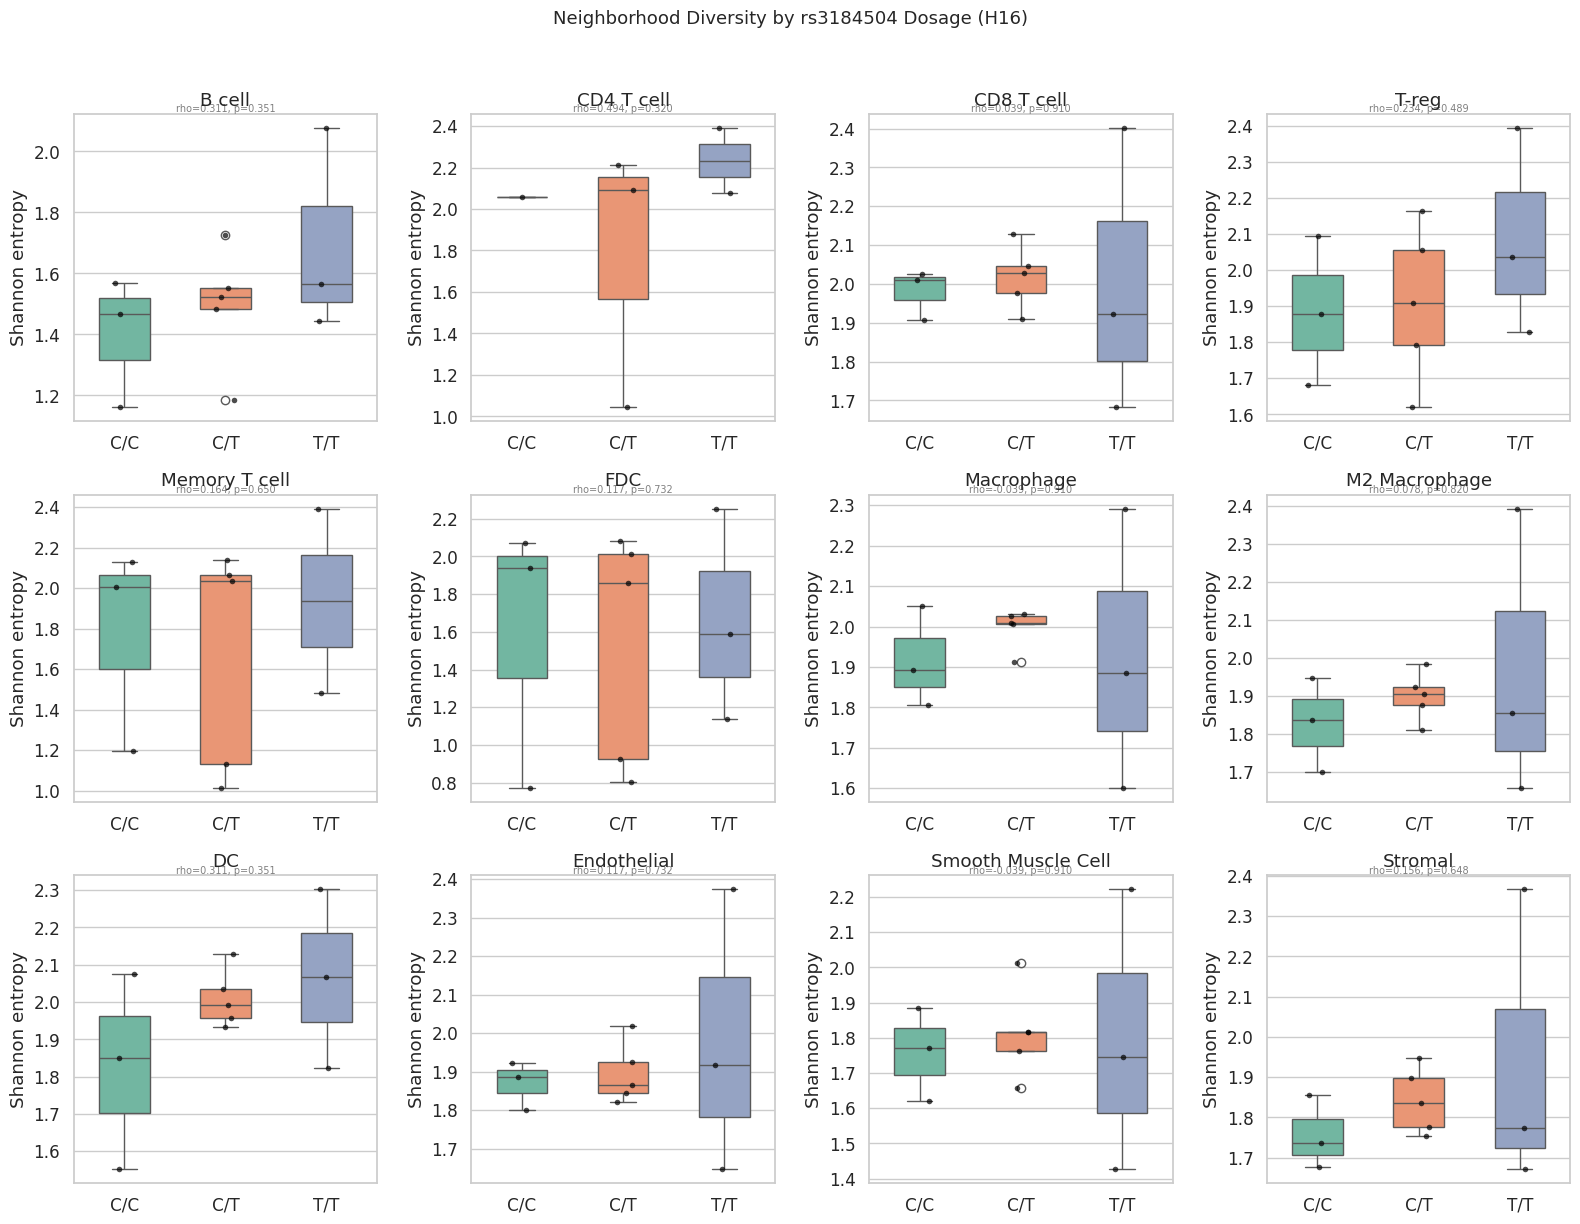

Saved: analysis/tables/H16_diversity_stats.csv
Significant (p < 0.1):
  None


In [31]:
# ── Neighborhood diversity by genotype ──
div_records = []
for (sample, ct), grp in neigh_df.groupby(["Sample", "cell_type"], observed=True):
    fracs = grp.set_index("neighbor_type")["frac"].values
    fracs = fracs[fracs > 0]
    if len(fracs) < 2:
        continue
    h = entropy(fracs)
    div_records.append({
        "Sample": sample,
        "Genotype": grp["Genotype"].iloc[0],
        "cell_type": ct,
        "Shannon_H": h,
    })

div_df = pd.DataFrame(div_records)

div_types = [ct for ct in CELL_TYPE_ORDER
             if ct in div_df["cell_type"].values and ct != "Other"]
n_dt = len(div_types)
ncols = min(4, n_dt)
nrows = (n_dt + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

div_stats = []
for i, ct in enumerate(div_types):
    ax = axes[i // ncols, i % ncols]
    sub = div_df[div_df["cell_type"] == ct].copy()
    sub["Genotype"] = sub["Genotype"].astype(str)
    sns.boxplot(data=sub, x="Genotype", y="Shannon_H", order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=sub, x="Genotype", y="Shannon_H", order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(ct); ax.set_xlabel(""); ax.set_ylabel("Shannon entropy")

    if len(sub) >= 3:
        stats = full_stats_table(sub, "Shannon_H", label=f"{ct} diversity")
        div_stats.append(stats)
        _annotate_dosage(ax, stats)

for j in range(n_dt, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Neighborhood Diversity by rs3184504 Dosage (H16)", fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H16_neighborhood_diversity")
plt.show()

if div_stats:
    div_stats_df = pd.concat(div_stats, ignore_index=True)
    div_stats_df = add_dosage_consistency_column(div_stats_df)
    save_table(div_stats_df, "H16_diversity_stats")

    dc_flags = flag_dosage_inconsistent(div_stats_df)
    if dc_flags:
        print("\nDosage consistency warnings:")
        for f in dc_flags:
            print(f"  {f}")

    sig = div_stats_df[div_stats_df["p"] < 0.1]
    print("Significant (p < 0.1):")
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")

---
## Spatial Cell Type Maps
Scatter plots of cells colored by assigned cell type within crop windows.

Saved: analysis/figures/H16_spatial_celltype_maps.png


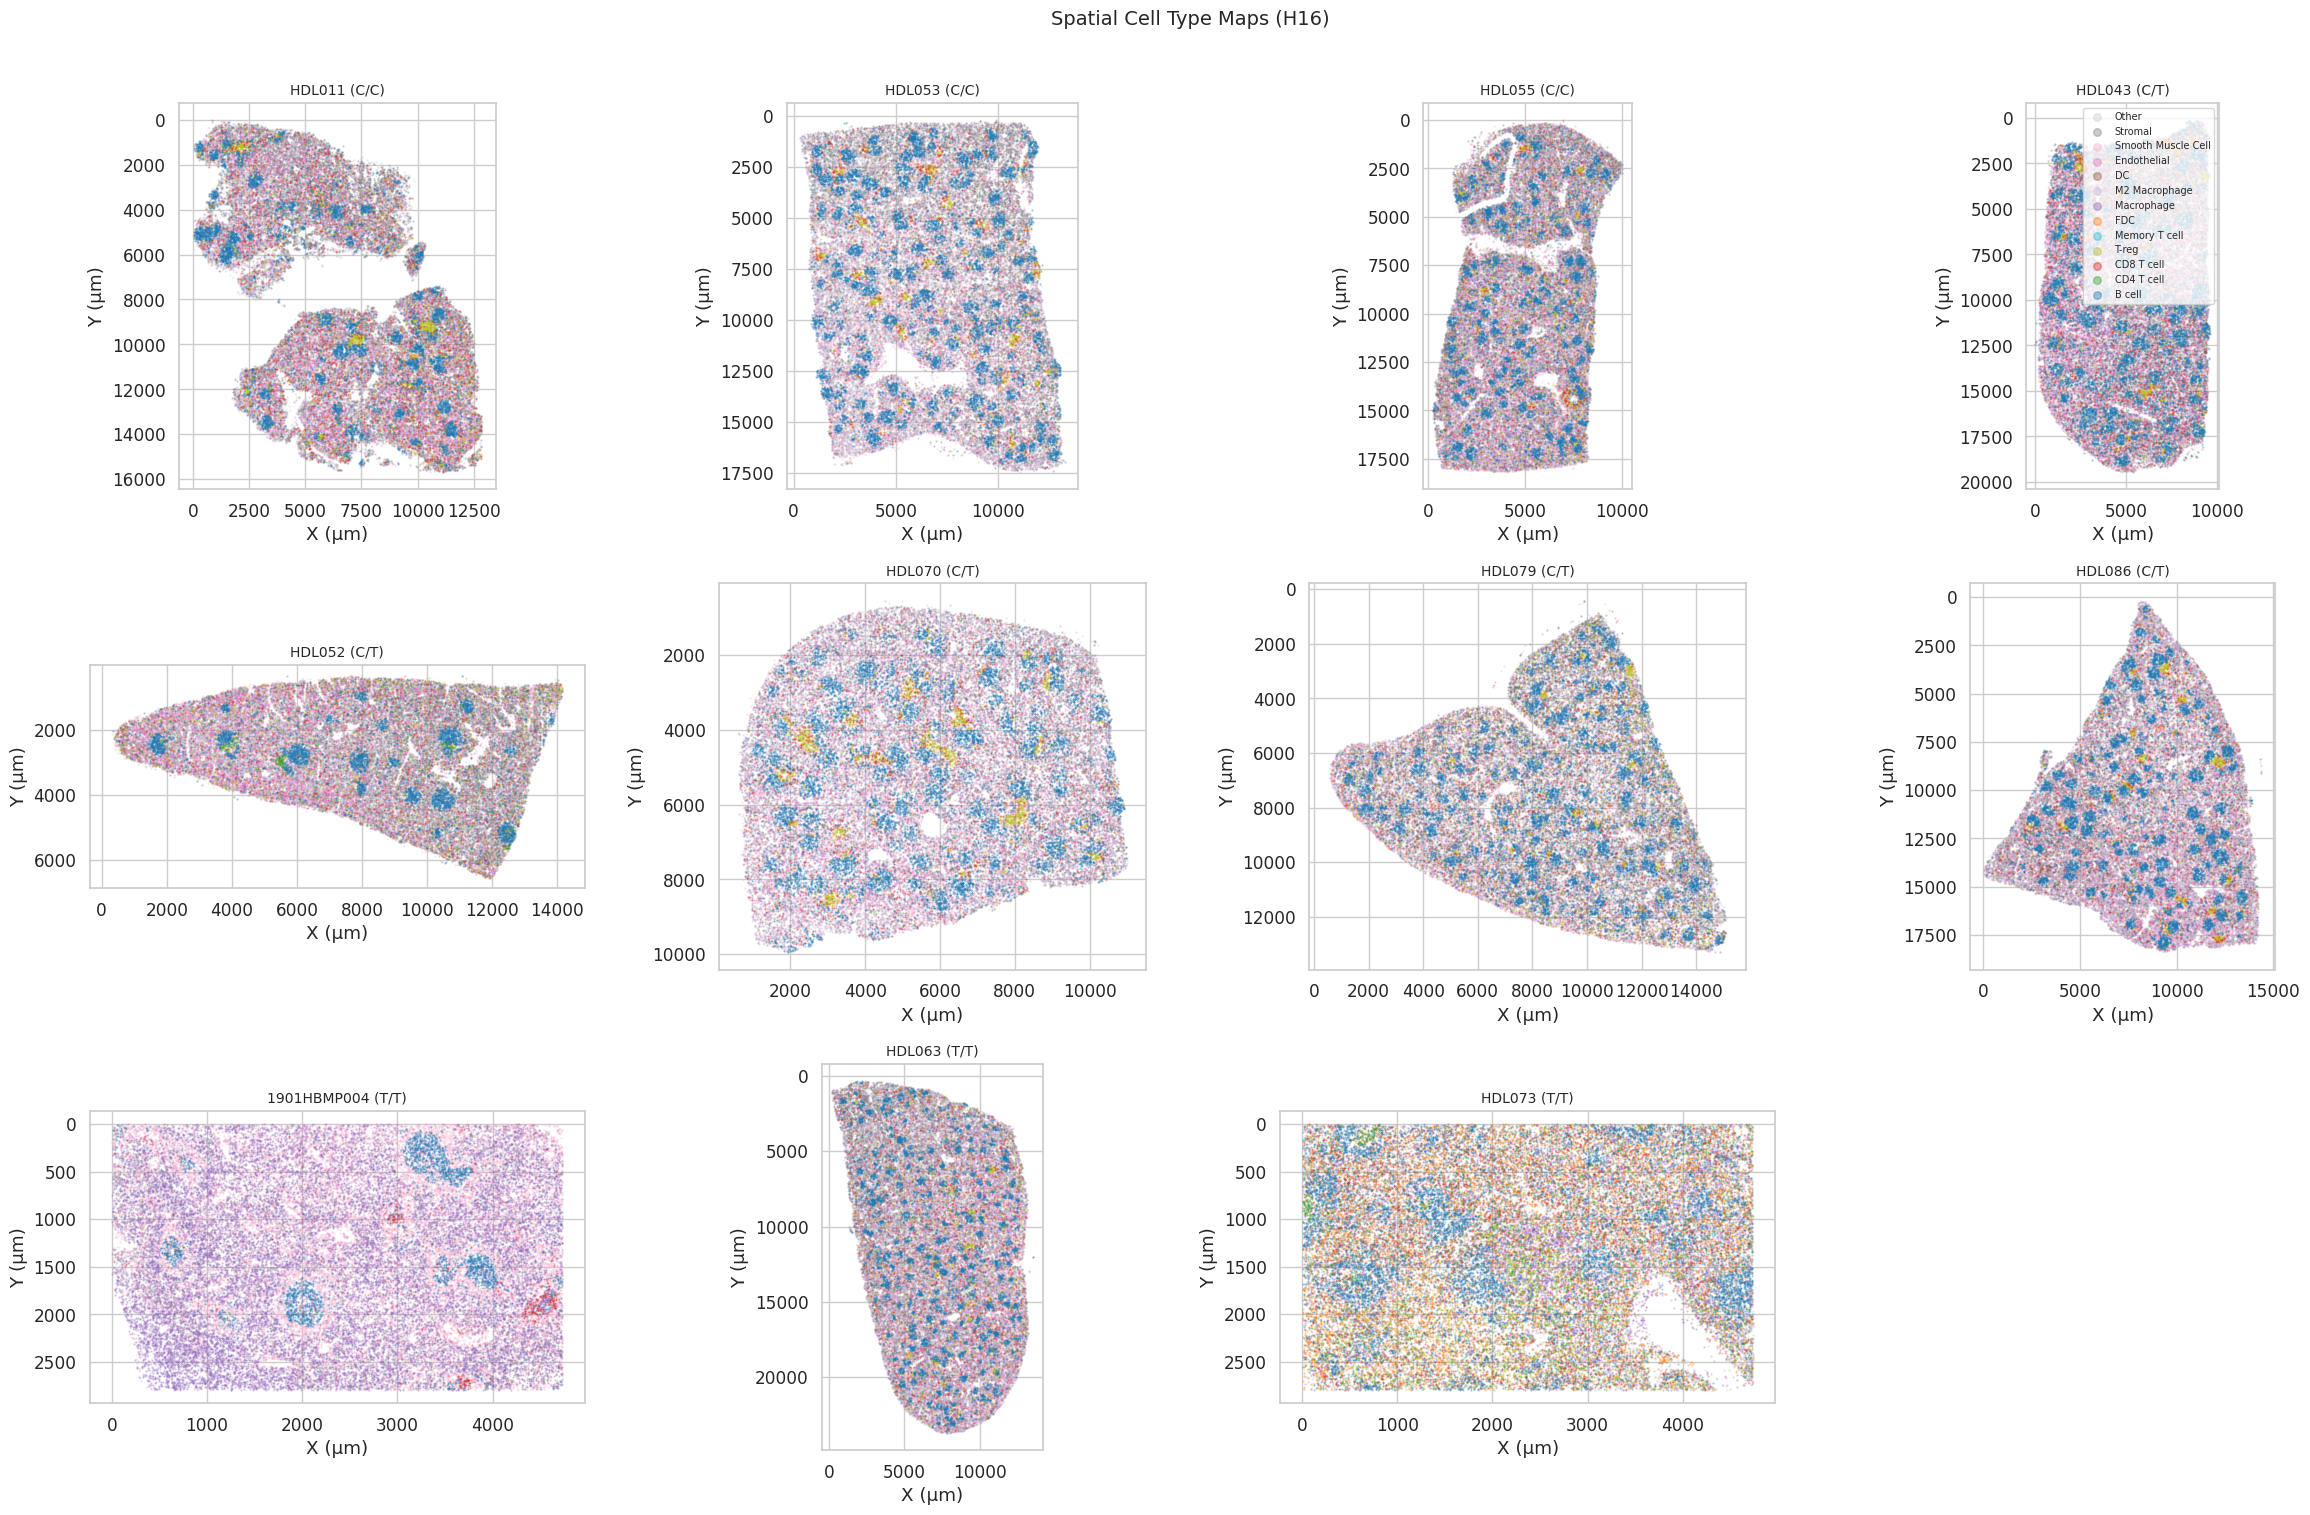

In [32]:
# ── Spatial cell type maps ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()

plot_samples = []
for geno in GENO_ORDER:
    geno_samples = sorted(obs_geno[obs_geno["Genotype"] == geno]["Sample"].unique())
    plot_samples.extend(geno_samples)

n_panels = len(plot_samples)
ncols = min(4, n_panels)
nrows = (n_panels + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

MAX_PLOT = 50_000
for i, sample in enumerate(plot_samples):
    ax = axes[i // ncols, i % ncols]
    s_data = obs_geno[obs_geno["Sample"] == sample]
    geno = s_data["Genotype"].iloc[0]

    if len(s_data) > MAX_PLOT:
        rng = np.random.default_rng(42)
        idx = rng.choice(len(s_data), MAX_PLOT, replace=False)
        s_data = s_data.iloc[idx]

    for ct in reversed(CELL_TYPE_ORDER):
        mask = s_data["cell_type"].values == ct
        if not mask.any():
            continue
        ax.scatter(s_data[X_COL].values[mask], s_data[Y_COL].values[mask],
                   c=ct_palette.get(ct, "grey"), s=0.3, alpha=0.4,
                   label=ct, rasterized=True)

    ax.set_title(f"{sample} ({geno})", fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("X (\u00b5m)"); ax.set_ylabel("Y (\u00b5m)")

axes[0, -1].legend(markerscale=10, fontsize=7, loc="upper right", frameon=True)

for j in range(n_panels, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Spatial Cell Type Maps (H16)", fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, "H16_spatial_celltype_maps")
plt.show()

---
## Summary

In [33]:
# ── Save checkpoint ──
adata.write_h5ad(PROJECT / "adata_H16.h5ad")
print(f"Saved: {PROJECT / 'adata_H16.h5ad'}")

# ── Key findings summary ──
print("=" * 60)
print("H16: Cluster-Based Cell Phenotyping — Summary")
print("=" * 60)
print(f"Total cells analyzed:   {adata.shape[0]:,}")
print(f"Markers (clustering):   {adata.shape[1]} (excluded: CollagenIV, Ecadherin)")
print(f"Overclusters:           {adata.obs['leiden_hi'].nunique()}")
print(f"Cell types assigned:    {adata.obs['cell_type'].nunique()}")
other_frac = (adata.obs['cell_type'] == 'Other').mean()
print(f"'Other' fraction:       {other_frac:.1%}")

obs_geno = adata.obs[adata.obs['Genotype'].notna()]
for g in GENO_ORDER:
    n = obs_geno[obs_geno['Genotype'] == g]['Sample'].nunique()
    print(f"  {g}: {n} samples")

print("\n--- Significant Genotype Associations (p < 0.1) ---")
for tbl_name in ["H16_celltype_genotype_stats", "H16_region_celltype_genotype_stats",
                 "H16_distance_genotype_stats",
                 "H16_neighborhood_genotype_stats", "H16_diversity_stats"]:
    path = PROJECT / "analysis" / "tables" / f"{tbl_name}.csv"
    if path.exists():
        tbl = pd.read_csv(path)
        sig = tbl[tbl["p"] < 0.1]
        if len(sig):
            print(f"\n  {tbl_name}:")
            for _, r in sig.iterrows():
                dc = f" [DOSAGE-INCONSISTENT]" if r.get("Dosage_Consistent") == "No" else ""
                print(f"    {r['Test']:30s} {r['Metric']:30s} p={r['p']:.4f}{dc}")

plat_path = PROJECT / "analysis" / "tables" / "H16_platform_diagnostic.csv"
if plat_path.exists():
    plat = pd.read_csv(plat_path)
    confounded = plat[plat["p"] < 0.1]["Feature"].tolist()
    if confounded:
        print(f"\nPlatform-confounded cell types: {confounded}")
    else:
        print("\nNo platform-confounded cell types.")

print("\nDone.")

Saved: /blue/maigan/smith6jt/SpleenFollicleCounterQP/adata_H16.h5ad
H16: Cluster-Based Cell Phenotyping — Summary
Total cells analyzed:   18,134,455
Markers (clustering):   20 (excluded: CollagenIV, Ecadherin)
Overclusters:           187
Cell types assigned:    13
'Other' fraction:       22.4%


  C/C: 3 samples


  C/T: 5 samples


  T/T: 3 samples

--- Significant Genotype Associations (p < 0.1) ---

  H16_celltype_genotype_stats:
    Mann-Whitney (C/C vs C/T)      Stromal                        p=0.0714 [DOSAGE-INCONSISTENT]
    Spearman dosage                Stromal                        p=0.0830 [DOSAGE-INCONSISTENT]

  H16_region_celltype_genotype_stats:
    Kruskal-Wallis                 PALS:M2 Macrophage             p=0.0471
    Mann-Whitney (C/C vs C/T)      PALS:M2 Macrophage             p=0.0357
    Spearman dosage                PALS:M2 Macrophage             p=0.0593
    Spearman dosage                PALS:DC                        p=0.0533
    Spearman dosage                PALS:Endothelial               p=0.0830
    Spearman dosage                PALS:Stromal                   p=0.0593
    Mann-Whitney (C/T vs T/T)      RedPulp:Endothelial            p=0.0714
    Kruskal-Wallis                 RedPulp:Stromal                p=0.0964
    Mann-Whitney (C/C vs C/T)      RedPulp:Stromal               